In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import kagglehub

path = kagglehub.dataset_download(
    "harshalhonde/property-rental-listings-dataset"
)

print(path)

100%|██████████| 987k/987k [00:00<00:00, 2.21MB/s]

Extracting files...
C:\Users\ahmed\.cache\kagglehub\datasets\harshalhonde\property-rental-listings-dataset\versions\2


In [3]:
from pathlib import Path

dataset_path = Path(path)

list(dataset_path.iterdir())

[WindowsPath('C:/Users/ahmed/.cache/kagglehub/datasets/harshalhonde/property-rental-listings-dataset/versions/2/Mumbai_property_details.csv')]

In [4]:
for file in dataset_path.iterdir():
    print(file.name)

Mumbai_property_details.csv


In [5]:
df = pd.read_csv(dataset_path / "Mumbai_property_details.csv")

df.head()

,Title,Price,Area,BHK,Bathrooms,Furnished,Balconies,Floor,Ownership,Facing,Amenities,Transaction Type,Property Type,Location,Year of Construction,Is Luxury,Description,Property Image
0,1BHK Multistorey Apartment for Rent in Bandra ...,"70,000",750 12800,1,1,Furnished,NaN,7,NaN,South -West,Main Road,Rent,Apartment,Mumbai,2012.0,F,"1 BHK, Multistorey Apartment is available for ...",67249079_2_PropertyImage345-4855396928822.jpg
1,3BHK Multistorey Apartment for Rent in Lodha N...,1.4 Lac,1980 12800,3,4,Unfurnished,4,21,NaN,East,"Garden/Park, Pool, Main Road",Rent,Apartment,Mumbai,1994.0,F,"3 BHK, Multistorey Apartment is available for ...",66155783_5_hatsAppImage20230217at13.56.28.jpeg
2,3BHK Multistorey Apartment for Rent in Lodha P...,1.9 Lac,1592 12800,3,3,Unfurnished,1,20,NaN,North - East,Main Road,Rent,Apartment,Mumbai,NaN,F,"3 BHK, Multistorey Apartment is available for ...",66686709_1_HOTO20230407165614.jpg
3,3BHK Multistorey Apartment for Rent in Rustomj...,1.1 Lac,1305 12800,3,3,Unfurnished,3,11,Freehold,West,"Garden/Park, Main Road",Rent,Apartment,Mumbai,2010.0,F,"3 BHK, Multistorey Apartment is available for ...",67875387_1_PropertyImage559-8385323621333.jpg
4,3BHK Multistorey Apartment for Rent in DLH The...,1.4 Lac,1350 12800,3,3,Unfurnished,NaN,29,Freehold,East,"Pool, Garden/Park, Main Road",Rent,Apartment,Mumbai,2000.0,F,"3 BHK, Multistorey Apartment is available for ...",66670931_3_PropertyImage314-6685675359874.jpg


In [6]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Shape: (23405, 18)

Columns:
['Title', 'Price', 'Area', 'BHK', 'Bathrooms', 'Furnished', 'Balconies', 'Floor', 'Ownership', 'Facing', 'Amenities', 'Transaction Type', 'Property Type', 'Location', 'Year of Construction', 'Is Luxury', 'Description', 'Property Image']

Data types:
Title                       str
Price                       str
Area                        str
BHK                         str
Bathrooms                   str
Furnished                   str
Balconies                   str
Floor                       str
Ownership                   str
Facing                      str
Amenities                   str
Transaction Type            str
Property Type               str
Location                    str
Year of Construction    float64
Is Luxury                   str
Description                 str
Property Image              str
dtype: object


In [7]:
missing = df.isnull().sum()

print(missing)

Title                       0
Price                       2
Area                        0
BHK                       411
Bathrooms                 204
Furnished                 189
Balconies               13017
Floor                    1120
Ownership               20570
Facing                   4281
Amenities                5313
Transaction Type            7
Property Type               0
Location                    0
Year of Construction     8520
Is Luxury                   2
Description                 0
Property Image           3798
dtype: int64


In [8]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 57434


In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 3111


In [10]:
print("Duplicate percentage:", 
      round(df.duplicated().mean() * 100, 2), "%")

Duplicate percentage: 13.29 %


In [11]:
df[df.duplicated(keep=False)].head(10)

,Title,Price,Area,BHK,Bathrooms,Furnished,Balconies,Floor,Ownership,Facing,Amenities,Transaction Type,Property Type,Location,Year of Construction,Is Luxury,Description,Property Image
196,2BHK Multistorey Apartment for Rent in Salsett...,1.3 Lac,788 12800,2,2,Semi-Furnished,NaN,9,NaN,West,"Garden/Park, Main Road",Rent,Apartment,Mumbai,NaN,F,"2 BHK, Multistorey Apartment is available for ...",67081047_1_alsette27elevation25975252.jpeg
197,2BHK Multistorey Apartment for Rent in Kandiva...,"40,000",1575 12800,2,2,Furnished,NaN,1,NaN,East,"Garden/Park, Main Road",Rent,Apartment,Mumbai,2018.0,F,"2 BHK, Multistorey Apartment is available for ...",67423677_4_hatsAppImage20230526at2.10.28PM.jpeg
198,3BHK Multistorey Apartment for Rent in Lodha M...,2.2 Lac,2000 12800,3,4,Unfurnished,NaN,50,NaN,East,"Main Road, Garden/Park",Rent,Apartment,Mumbai,2017.0,F,"3 BHK, Multistorey Apartment is available for ...",66506231_1_1681114880329-963.jpg
199,3BHK Multistorey Apartment for Rent in Mahavir...,"50,000",1177 12800,3,2,Unfurnished,NaN,9,NaN,East,"Garden/Park, Pool",Rent,Apartment,Mumbai,2001.0,F,"3 BHK, Multistorey Apartment is available for ...",68039105_4_PropertyImage617-3128014199034.jpg
200,3BHK Multistorey Apartment for Rent in Hiranan...,1.2 Lac,1400 12800,3,3,Furnished,NaN,11,NaN,East,Garden/Park,Rent,Apartment,Mumbai,2014.0,F,"3 BHK, Multistorey Apartment is available for ...",63722267_11_PropertyImage543-3112827294095.jpg
201,2BHK Multistorey Apartment for Rent in Gorwani...,1.5 Lac,800 12800,2,3,Furnished,NaN,7,NaN,South,Main Road,Rent,Apartment,Mumbai,2010.0,F,"2 BHK, Multistorey Apartment is available for ...",67849183_2_hatsAppImage20230703at12.33.26PM2.jpeg
202,3BHK Multistorey Apartment for Rent in White C...,"84,000",1760 12800,3,3,Semi-Furnished,NaN,Upper Basement,NaN,East,"Garden/Park, Main Road",Rent,Apartment,Mumbai,2015.0,F,"3 BHK, Multistorey Apartment is available for ...",Project-Photo-24-White-City-Mumbai-5019193_535...
203,3BHK Multistorey Apartment for Rent in City Of...,"50,000",1260 12800,3,3,Semi-Furnished,NaN,5,NaN,East,Garden/Park,Rent,Apartment,Mumbai,NaN,F,"3 BHK, Multistorey Apartment is available for ...",Project-Photo-1-City-Of-Joy-Mumbai-5000228_479...
204,2BHK Multistorey Apartment for Rent in Tahnee ...,3.5 Lac,2200 12800,2,2,Semi-Furnished,NaN,NaN,NaN,East,Main Road,Rent,Apartment,Mumbai,NaN,F,"2 BHK, Multistorey Apartment is available for ...",Project-Photo-3-Tahnee-Heights-Mumbai-5062837_...
205,3BHK Multistorey Apartment for Rent in Marina ...,"55,000",1211 12800,3,3,Unfurnished,NaN,15,NaN,North - East,Garden/Park,Rent,Apartment,Mumbai,2008.0,F,"3 BHK, Multistorey Apartment is available for ...",Project-Photo-14-Marina-Enclave-Mumbai-5074616...


In [12]:
duplicates = df[df.duplicated()]

print("Exact duplicate rows to remove:", len(duplicates))
duplicates.head()

Exact duplicate rows to remove: 3111


,Title,Price,Area,BHK,Bathrooms,Furnished,Balconies,Floor,Ownership,Facing,Amenities,Transaction Type,Property Type,Location,Year of Construction,Is Luxury,Description,Property Image
997,1BHK Multistorey Apartment for Rent in Omkar M...,"55,000",700 12800,1,1,Semi-Furnished,NaN,1,NaN,NaN,NaN,Rent,Apartment,Mumbai,NaN,F,"1 BHK, Multistorey Apartment is available for ...",Project-Photo-1-Omkar-Meridia-Mumbai-5026784_4...
1380,1BHK Multistorey Apartment for Rent in Virar West,"8,500",675 12800,1,2,Semi-Furnished,NaN,9,NaN,NaN,NaN,Rent,Apartment,Mumbai,NaN,F,"1 BHK, Multistorey Apartment is available for ...",NaN
2004,1BHK Multistorey Apartment for Rent in Hill pa...,"28,000",550 12800,1,1,Unfurnished,NaN,4,NaN,NaN,Garden/Park,Rent,Apartment,Mumbai,NaN,F,"1 BHK, Multistorey Apartment is available for ...",NaN
2314,1BHK Residential House for Rent in Kandivali East,"7,000",200 12800,1,1,Unfurnished,NaN,1,NaN,NaN,NaN,Rent,Residential House,Mumbai,NaN,F,"1 BHK, Residential House is available for Rent...",NaN
3188,Multistorey Apartment for Rent in,Call for Price,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Rent,Apartment,Mumbai,NaN,F,Multistorey Apartment is available for Rent ...,NaN


In [13]:
print(df["Price"].value_counts().head(20))

Price
65,000     824
45,000     730
60,000     697
75,000     685
55,000     680
1.3 Lac    660
50,000     654
1.5 Lac    646
40,000     634
70,000     609
1.2 Lac    602
35,000     601
80,000     573
1.1 Lac    563
85,000     524
1 Lac      501
90,000     460
1.4 Lac    390
30,000     376
1.8 Lac    365
Name: count, dtype: int64


In [14]:
print(df["Area"].value_counts().head(20))

Area
None          1069
1000 12800     893
1200 12800     790
650 12800      768
1100 12800     647
1050 12800     578
900 12800      577
600 12800      567
1500 12800     552
1250 12800     537
850 12800      445
950 12800      438
700 12800      432
750 12800      417
1150 12800     371
550 12800      366
800 12800      363
1800 12800     349
500 12800      328
1600 12800     321
Name: count, dtype: int64


In [15]:
print(df["BHK"].value_counts(dropna=False).head(20))

BHK
2       9260
1       6038
3       5884
4       1515
NaN      411
5        244
6         40
7         10
> 10       3
Name: count, dtype: int64


In [16]:
print(df["Area"].head(20).to_list())

['750 12800', '1980 12800', '1592 12800', '1305 12800', '1350 12800', '2000 12800', '2150 12800', '737 12800', '910 12800', '700 12800', '2100 12800', '2120 12800', '1475 12800', '425 12800', '1312 12800', '695 12800', '3450 12800', '4300 12800', '1000 12800', '850 12800']


In [17]:
print(df["Area"].tail(20).to_list())

['6000 12800', '250 12800', '560 12800', '1000 12800', '1050 12800', '2 12800', '530 12800', '655 12800', '985 12800', '20 12800', '2590 12800', '650 12800', '480 12800', '600 12800', 'None ', '500 12800', 'None ', 'None ', '25 12800', '25 12800']


In [18]:
print(df["Area"].str.contains("12800", na=False).sum())

22312


In [19]:
print(df["Area"].str.replace(" 12800", "", regex=False).head(20).to_list())

['750', '1980', '1592', '1305', '1350', '2000', '2150', '737', '910', '700', '2100', '2120', '1475', '425', '1312', '695', '3450', '4300', '1000', '850']


In [20]:
print(df.loc[~df["Area"].str.contains("12800", na=False), "Area"].value_counts().head(30))

Area
None          1069
53 12801         4
32 12801         3
130 12803        2
73 12801         2
250 12801        2
30 12801         2
82 12801         1
2000 12810       1
950 12805        1
1900 12806       1
800 12801        1
700 12803        1
670 12807        1
367 12807        1
900 12808        1
Name: count, dtype: int64


In [21]:
print(df["Area"].str.extract(r"^(\d+)")[0].head(20).to_list())

['750', '1980', '1592', '1305', '1350', '2000', '2150', '737', '910', '700', '2100', '2120', '1475', '425', '1312', '695', '3450', '4300', '1000', '850']


In [22]:
area_extracted = df["Area"].str.extract(r"^(\d+)")[0]

print("Valeurs manquantes après extraction :", area_extracted.isna().sum())
print("\nValeurs qui n'ont pas pu être extraites :")
print(df.loc[area_extracted.isna(), "Area"].value_counts(dropna=False))

Valeurs manquantes après extraction : 1073

Valeurs qui n'ont pas pu être extraites :
Area
None          1069
None 12800       4
Name: count, dtype: int64


In [23]:
print("Minimum :", pd.to_numeric(area_extracted, errors="coerce").min())
print("Maximum :", pd.to_numeric(area_extracted, errors="coerce").max())

print("\nPlus petites valeurs :")
print(pd.to_numeric(area_extracted, errors="coerce").sort_values().head(20).to_list())

print("\nPlus grandes valeurs :")
print(pd.to_numeric(area_extracted, errors="coerce").sort_values().tail(20).to_list())

Minimum : 2.0
Maximum : 9588.0

Plus petites valeurs :
[2.0, 10.0, 10.0, 10.0, 10.0, 10.0, 11.0, 12.0, 12.0, 12.0, 12.0, 13.0, 14.0, 15.0, 15.0, 15.0, 20.0, 25.0, 25.0, 30.0]

Plus grandes valeurs :
[nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]


In [24]:
df_clean = df.copy()

df_clean["Area"] = pd.to_numeric(
    df_clean["Area"].str.extract(r"^(\d+)")[0],
    errors="coerce"
)

print(df_clean["Area"].head())
print("\nType :", df_clean["Area"].dtype)

0     750.0
1    1980.0
2    1592.0
3    1305.0
4    1350.0
Name: Area, dtype: float64

Type : float64


In [25]:
print(df["Price"].value_counts(dropna=False).head(30))

Price
65,000     824
45,000     730
60,000     697
75,000     685
55,000     680
1.3 Lac    660
50,000     654
1.5 Lac    646
40,000     634
70,000     609
1.2 Lac    602
35,000     601
80,000     573
1.1 Lac    563
85,000     524
1 Lac      501
90,000     460
1.4 Lac    390
30,000     376
1.8 Lac    365
2 Lac      328
95,000     310
25,000     305
15,000     296
2.5 Lac    288
1.6 Lac    287
38,000     230
20,000     226
1.7 Lac    225
42,000     223
Name: count, dtype: int64


In [26]:
print(
    df["Price"]
    .dropna()
    .astype(str)
    .str.extract(r"([A-Za-z]+)$")[0]
    .value_counts()
)

0
Lac      7122
Price     217
Cr         19
Name: count, dtype: int64


In [27]:
print("Valeurs avec Cr :")
print(df.loc[df["Price"].astype(str).str.endswith("Cr"), "Price"].value_counts())

print("\nValeurs avec Price :")
print(df.loc[df["Price"].astype(str).str.endswith("Price"), "Price"].value_counts())

Valeurs avec Cr :
Price
1 Cr       6
3.50 Cr    4
3 Cr       2
1.45 Cr    2
1.35 Cr    2
1.10 Cr    1
4 Cr       1
1.30 Cr    1
Name: count, dtype: int64

Valeurs avec Price :
Price
Call for Price    217
Name: count, dtype: int64


In [28]:
print(
    df.loc[
        df["Price"].astype(str).str.endswith("Lac"),
        "Price"
    ].value_counts().head(30)
)

Price
1.3 Lac    660
1.5 Lac    646
1.2 Lac    602
1.1 Lac    563
1 Lac      501
1.4 Lac    390
1.8 Lac    365
2 Lac      328
2.5 Lac    288
1.6 Lac    287
1.7 Lac    225
2.3 Lac    198
3.5 Lac    194
3 Lac      176
1.9 Lac    137
2.8 Lac    135
4 Lac      118
4.5 Lac    108
5 Lac       98
2.2 Lac     81
2.4 Lac     76
3.3 Lac     75
4.3 Lac     67
2.1 Lac     64
2.7 Lac     53
3.8 Lac     48
2.6 Lac     44
6 Lac       40
7 Lac       38
4.8 Lac     37
Name: count, dtype: int64


In [29]:
def convert_price(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    if value == "Call for Price":
        return np.nan

    if value.endswith("Lac"):
        number = float(value.replace("Lac", "").strip())
        return number * 100_000

    if value.endswith("Cr"):
        number = float(value.replace("Cr", "").strip())
        return number * 10_000_000

    return float(value.replace(",", ""))


price_test = df["Price"].apply(convert_price)

print(price_test.head(20))
print("\nType :", price_test.dtype)

0      70000.0
1     140000.0
2     190000.0
3     110000.0
4     140000.0
5     140000.0
6     300000.0
7      80000.0
8     150000.0
9      55000.0
10    270000.0
11    250000.0
12     85500.0
13     40000.0
14    130000.0
15     50000.0
16    450000.0
17    450000.0
18    150000.0
19     85000.0
Name: Price, dtype: float64

Type : float64


In [30]:
test_values = ["65,000", "1.3 Lac", "1 Lac", "1.45 Cr", "3.50 Cr", "Call for Price"]

for value in test_values:
    print(f"{value} -> {convert_price(value)}")

65,000 -> 65000.0
1.3 Lac -> 130000.0
1 Lac -> 100000.0
1.45 Cr -> 14500000.0
3.50 Cr -> 35000000.0
Call for Price -> nan


In [31]:
df_clean["Price"] = df["Price"].apply(convert_price)

print(df_clean["Price"].head(20))
print("\nType :", df_clean["Price"].dtype)
print("\nValeurs manquantes :", df_clean["Price"].isna().sum())

0      70000.0
1     140000.0
2     190000.0
3     110000.0
4     140000.0
5     140000.0
6     300000.0
7      80000.0
8     150000.0
9      55000.0
10    270000.0
11    250000.0
12     85500.0
13     40000.0
14    130000.0
15     50000.0
16    450000.0
17    450000.0
18    150000.0
19     85000.0
Name: Price, dtype: float64

Type : float64

Valeurs manquantes : 219


In [32]:
print(df["BHK"].value_counts(dropna=False))

BHK
2       9260
1       6038
3       5884
4       1515
NaN      411
5        244
6         40
7         10
> 10       3
Name: count, dtype: int64


In [33]:
print(df.loc[df["BHK"] == "> 10", ["Title", "BHK", "Property Type", "Location"]])

                                                   Title   BHK  \
790    > 10BHK Builder Floor Apartment for Rent in Ma...  > 10   
13133  > 10BHK Builder Floor Apartment for Rent in Ma...  > 10   
17359  > 10BHK Multistorey Apartment for Rent in Cart...  > 10   

                 Property Type Location  
790    Builder Floor Apartment   Mumbai  
13133  Builder Floor Apartment   Mumbai  
17359                Apartment   Mumbai  


In [34]:
print(df["BHK"].dropna().unique())

<StringArray>
['1', '3', '4', '2', '7', '5', '6', '> 10']
Length: 8, dtype: str


In [35]:
df_clean["BHK"] = pd.to_numeric(
    df_clean["BHK"].replace("> 10", np.nan),
    errors="coerce"
)

print(df_clean["BHK"].value_counts(dropna=False).sort_index())
print("\nType :", df_clean["BHK"].dtype)

BHK
1.0    6038
2.0    9260
3.0    5884
4.0    1515
5.0     244
6.0      40
7.0      10
NaN     414
Name: count, dtype: int64

Type : float64


In [36]:
print(df["Bathrooms"].value_counts(dropna=False))

Bathrooms
2       11989
3        4835
1        4052
4        1645
5         516
NaN       204
6         132
7          20
8           8
> 10        2
9           1
10          1
Name: count, dtype: int64


In [37]:
print(
    df.loc[
        df["Bathrooms"] == "> 10",
        ["Title", "Bathrooms", "BHK", "Property Type", "Location"]
    ]
)

                                                   Title Bathrooms   BHK  \
790    > 10BHK Builder Floor Apartment for Rent in Ma...      > 10  > 10   
13133  > 10BHK Builder Floor Apartment for Rent in Ma...      > 10  > 10   

                 Property Type Location  
790    Builder Floor Apartment   Mumbai  
13133  Builder Floor Apartment   Mumbai  


In [38]:
df_clean["Bathrooms"] = pd.to_numeric(
    df_clean["Bathrooms"].replace("> 10", np.nan),
    errors="coerce"
)

print(df_clean["Bathrooms"].value_counts(dropna=False).sort_index())
print("\nType :", df_clean["Bathrooms"].dtype)

Bathrooms
1.0      4052
2.0     11989
3.0      4835
4.0      1645
5.0       516
6.0       132
7.0        20
8.0         8
9.0         1
10.0        1
NaN       206
Name: count, dtype: int64

Type : float64


In [39]:
print(df["Balconies"].value_counts(dropna=False))

Balconies
NaN     13017
1        5191
2        2675
3        1756
4         589
5         138
6          24
7           5
9           3
8           3
10          3
> 10        1
Name: count, dtype: int64


In [40]:
print(df["Balconies"].value_counts(dropna=False))

Balconies
NaN     13017
1        5191
2        2675
3        1756
4         589
5         138
6          24
7           5
9           3
8           3
10          3
> 10        1
Name: count, dtype: int64


In [41]:
print(
    df.loc[
        df["Balconies"] == "> 10",
        ["Title", "Balconies", "BHK", "Bathrooms", "Property Type", "Location"]
    ]
)

                                                  Title Balconies BHK  \
5976  3BHK Multistorey Apartment for Rent in Lower P...      > 10   3   

     Bathrooms Property Type Location  
5976         3     Apartment   Mumbai  


In [42]:
df_clean["Balconies"] = pd.to_numeric(
    df_clean["Balconies"].replace("> 10", np.nan),
    errors="coerce"
)

print(df_clean["Balconies"].value_counts(dropna=False).sort_index())
print("\nType :", df_clean["Balconies"].dtype)

Balconies
1.0      5191
2.0      2675
3.0      1756
4.0       589
5.0       138
6.0        24
7.0         5
8.0         3
9.0         3
10.0        3
NaN     13018
Name: count, dtype: int64

Type : float64


In [43]:
print(df["Floor"].value_counts(dropna=False).head(30))

Floor
5                 2087
4                 1871
3                 1743
2                 1572
7                 1345
10                1326
6                 1282
1                 1256
NaN               1120
9                 1008
8                  935
12                 886
11                 732
15                 618
Ground             557
14                 533
16                 429
18                 385
20                 378
13                 352
Upper Basement     333
17                 313
19                 234
22                 188
30                 173
21                 165
25                 154
24                 107
23                 104
26                  93
Name: count, dtype: int64


In [44]:
print(df["Floor"].dropna().unique())

<StringArray>
[             '7',             '21',             '20',             '11',
             '29',             '60',             '10',              '6',
              '8',             '15',             '13',             '25',
              '5',              '9',              '2',             '46',
              '3',             '16',             '17',             '48',
             '18',              '4',             '37',             '26',
             '12',              '1',             '30',             '14',
             '39',             '24',             '35',             '23',
             '50',             '22',             '59',             '38',
         'Ground',             '19',             '65',             '45',
             '34',             '33',             '43', 'Upper Basement',
             '28',             '47',             '31',             '27',
             '40',             '32',             '44', 'Lower Basement',
             '36',             '41', 

In [45]:
print(df["Floor"].value_counts().loc[["Ground", "Upper Basement", "Lower Basement"]])

Floor
Ground            557
Upper Basement    333
Lower Basement     64
Name: count, dtype: int64


In [46]:
df_clean["Floor"] = (
    df_clean["Floor"]
    .replace({
        "Lower Basement": -2,
        "Upper Basement": -1,
        "Ground": 0
    })
)

df_clean["Floor"] = pd.to_numeric(
    df_clean["Floor"],
    errors="coerce"
)

print(df_clean["Floor"].value_counts(dropna=False).sort_index())
print("\nType :", df_clean["Floor"].dtype)

Floor
-2.0       64
-1.0      333
 0.0      557
 1.0     1256
 2.0     1572
         ... 
 74.0       3
 75.0       1
 76.0       1
 77.0       1
 NaN     1120
Name: count, Length: 81, dtype: int64

Type : float64


In [47]:
print(df["Ownership"].value_counts(dropna=False))

Ownership
NaN                     20570
Freehold                 1908
Co-operative Society      755
Leasehold                 152
Power Of Attorney          20
Name: count, dtype: int64


In [48]:
print(
    df.loc[
        df["Ownership"].isna(),
        ["Title", "Property Type", "Location", "Price", "BHK"]
    ].head(20)
)

                                                Title Property Type Location  \
0   1BHK Multistorey Apartment for Rent in Bandra ...     Apartment   Mumbai   
1   3BHK Multistorey Apartment for Rent in Lodha N...     Apartment   Mumbai   
2   3BHK Multistorey Apartment for Rent in Lodha P...     Apartment   Mumbai   
5   3BHK Multistorey Apartment for Rent in Insigni...     Apartment   Mumbai   
6   4BHK Multistorey Apartment for Rent in Lodha P...     Apartment   Mumbai   
8   3BHK Multistorey Apartment for Rent in DLH The...     Apartment   Mumbai   
9   1BHK Multistorey Apartment for Rent in Godrej ...     Apartment   Mumbai   
10  3BHK Multistorey Apartment for Rent in Raheja ...     Apartment   Mumbai   
11  4BHK Multistorey Apartment for Rent in Lodha M...     Apartment   Mumbai   
12  3BHK Multistorey Apartment for Rent in Ashford...     Apartment   Mumbai   
13  1BHK Multistorey Apartment for Rent in Veena S...     Apartment   Mumbai   
14  2BHK Multistorey Apartment for Rent 

In [49]:
print(
    df.loc[df["Ownership"].isna(), "Property Type"]
    .value_counts()
)

Property Type
Apartment                  19253
Residential House            724
Studio Apartment             238
Builder Floor Apartment      230
Villa                         96
Penthouse                     25
Service Apartment              4
Name: count, dtype: int64


In [50]:
print(df["Facing"].value_counts(dropna=False))

Facing
East            10713
NaN              4281
North - East     2975
West             2119
North            1547
South -West       739
North - West      457
South - East      305
South             269
Name: count, dtype: int64


In [51]:
print(df["Facing"].dropna().unique())

<StringArray>
[ 'South -West',         'East', 'North - East',         'West',
        'North', 'South - East', 'North - West',        'South']
Length: 8, dtype: str


In [52]:
print(df["Amenities"].value_counts(dropna=False).head(20))

Amenities
Main Road                       5409
NaN                             5313
Garden/Park                     4206
Garden/Park, Main Road          3737
Garden/Park, Pool, Main Road    2376
Pool, Garden/Park, Main Road     803
Garden/Park, Pool                605
Pool                             240
Main Road, Garden/Park           238
Pool, Garden/Park                182
Main Road, Garden/Park, Pool     137
Pool, Main Road                   97
Garden/Park, Main Road, Pool      37
Pool, Main Road, Garden/Park      12
Main Road, Pool, Garden/Park       7
Main Road, Pool                    5
Main Road, Not Available           1
Name: count, dtype: int64


In [53]:
print(df["Transaction Type"].value_counts(dropna=False))

Transaction Type
Rent    23398
NaN         7
Name: count, dtype: int64


In [54]:
print(df["Property Type"].value_counts(dropna=False))

Property Type
Apartment                  22026
Residential House            746
Studio Apartment             261
Builder Floor Apartment      232
Villa                        107
Penthouse                     29
Service Apartment              4
Name: count, dtype: int64


In [55]:
print(df["Location"].value_counts(dropna=False))

Location
Mumbai    23405
Name: count, dtype: int64


In [56]:
print(df["Year of Construction"].value_counts(dropna=False).head(30))

Year of Construction
NaN       8520
2010.0    1656
2000.0    1081
2005.0    1009
2012.0     977
2007.0     931
2009.0     700
2015.0     680
2008.0     672
2011.0     616
2014.0     601
2019.0     580
2013.0     524
2016.0     516
2006.0     320
2017.0     312
1998.0     312
1995.0     310
2001.0     297
1990.0     226
1992.0     224
1999.0     219
1985.0     205
1996.0     202
2002.0     197
2003.0     189
2004.0     178
2018.0     130
1997.0     119
1994.0     102
Name: count, dtype: int64


In [57]:
print("Minimum :", df["Year of Construction"].min())
print("Maximum :", df["Year of Construction"].max())

Minimum : 1914.0
Maximum : 2023.0


In [58]:
print(df["Is Luxury"].value_counts(dropna=False))

Is Luxury
F      23403
NaN        2
Name: count, dtype: int64


In [59]:
print("Nombre de valeurs contenant 12800 :", 
      df["Area"].str.contains("12800", na=False).sum())

print("\nExemples sans le suffixe 12800 :")
print(
    df["Area"]
    .str.replace(" 12800", "", regex=False)
    .head(20)
    .to_list()
)

Nombre de valeurs contenant 12800 : 22312

Exemples sans le suffixe 12800 :
['750', '1980', '1592', '1305', '1350', '2000', '2150', '737', '910', '700', '2100', '2120', '1475', '425', '1312', '695', '3450', '4300', '1000', '850']


In [60]:
area_without_suffix = df.loc[
    ~df["Area"].str.contains("12800", na=False),
    "Area"
]

print(area_without_suffix.value_counts(dropna=False).head(30))

Area
None          1069
53 12801         4
32 12801         3
130 12803        2
73 12801         2
250 12801        2
30 12801         2
82 12801         1
2000 12810       1
950 12805        1
1900 12806       1
800 12801        1
700 12803        1
670 12807        1
367 12807        1
900 12808        1
Name: count, dtype: int64


In [61]:
area_test = df["Area"].str.extract(r"^(\d+(?:\.\d+)?)")[0]

print(area_test.head(20))
print("\nType:", area_test.dtype)
print("\nMissing values:", area_test.isna().sum())

0      750
1     1980
2     1592
3     1305
4     1350
5     2000
6     2150
7      737
8      910
9      700
10    2100
11    2120
12    1475
13     425
14    1312
15     695
16    3450
17    4300
18    1000
19     850
Name: 0, dtype: str

Type: str

Missing values: 1073


In [62]:
df_clean["Area"] = pd.to_numeric(
    df["Area"].str.extract(r"^(\d+(?:\.\d+)?)")[0],
    errors="coerce"
)

print(df_clean["Area"].head(20))
print("\nType:", df_clean["Area"].dtype)
print("\nMissing values:", df_clean["Area"].isna().sum())

0      750.0
1     1980.0
2     1592.0
3     1305.0
4     1350.0
5     2000.0
6     2150.0
7      737.0
8      910.0
9      700.0
10    2100.0
11    2120.0
12    1475.0
13     425.0
14    1312.0
15     695.0
16    3450.0
17    4300.0
18    1000.0
19     850.0
Name: Area, dtype: float64

Type: float64

Missing values: 1073


In [63]:
print(
    df.loc[df["Ownership"].isna(), "Property Type"]
    .value_counts()
)

Property Type
Apartment                  19253
Residential House            724
Studio Apartment             238
Builder Floor Apartment      230
Villa                         96
Penthouse                     25
Service Apartment              4
Name: count, dtype: int64


In [64]:
df_clean["Ownership"] = df_clean["Ownership"].fillna("Unknown")

print(df_clean["Ownership"].value_counts())

Ownership
Unknown                 20570
Freehold                 1908
Co-operative Society      755
Leasehold                 152
Power Of Attorney          20
Name: count, dtype: int64


In [65]:
print(df["Facing"].dropna().unique())

<StringArray>
[ 'South -West',         'East', 'North - East',         'West',
        'North', 'South - East', 'North - West',        'South']
Length: 8, dtype: str


In [66]:
df_clean["Facing"] = df_clean["Facing"].fillna("Unknown")

print(df_clean["Facing"].value_counts())

Facing
East            10713
Unknown          4281
North - East     2975
West             2119
North            1547
South -West       739
North - West      457
South - East      305
South             269
Name: count, dtype: int64


In [67]:
print(df["Amenities"].dropna().unique())

<StringArray>
[                   'Main Road', 'Garden/Park, Pool, Main Road',
       'Garden/Park, Main Road', 'Pool, Garden/Park, Main Road',
                         'Pool',            'Pool, Garden/Park',
                  'Garden/Park',       'Main Road, Garden/Park',
            'Garden/Park, Pool', 'Main Road, Garden/Park, Pool',
              'Pool, Main Road', 'Garden/Park, Main Road, Pool',
 'Pool, Main Road, Garden/Park',              'Main Road, Pool',
 'Main Road, Pool, Garden/Park',    'Main Road, Not Available ']
Length: 16, dtype: str


In [68]:
df_clean["Amenities"] = df_clean["Amenities"].fillna("Unknown")

print(df_clean["Amenities"].value_counts())

Amenities
Main Road                       5409
Unknown                         5313
Garden/Park                     4206
Garden/Park, Main Road          3737
Garden/Park, Pool, Main Road    2376
Pool, Garden/Park, Main Road     803
Garden/Park, Pool                605
Pool                             240
Main Road, Garden/Park           238
Pool, Garden/Park                182
Main Road, Garden/Park, Pool     137
Pool, Main Road                   97
Garden/Park, Main Road, Pool      37
Pool, Main Road, Garden/Park      12
Main Road, Pool, Garden/Park       7
Main Road, Pool                    5
Main Road, Not Available           1
Name: count, dtype: int64


In [69]:
print(df["Transaction Type"].value_counts(dropna=False))

Transaction Type
Rent    23398
NaN         7
Name: count, dtype: int64


In [70]:
print(
    df.loc[
        df["Transaction Type"].isna(),
        ["Title", "Price", "BHK", "Property Type", "Location"]
    ]
)

                                                   Title    Price  BHK  \
1273   2BHK Residential House in Dosti Residency at V...    7,500    2   
3155   2BHK Builder Floor Apartment for Rent in Andhe...      NaN  NaN   
6933   3BHK Multistorey Apartment in Serenity Apartme...    2 Lac    3   
9373   3BHK Multistorey Apartment in Amber Apartment ...  1.8 Lac    3   
10696  3BHK Multistorey Apartment in Serenity Apartme...    2 Lac    3   
19378  2BHK Residential House in Dosti Residency at V...    7,500    2   
23267  2BHK Builder Floor Apartment for Rent in Andhe...      NaN  NaN   

                 Property Type Location  
1273         Residential House   Mumbai  
3155   Builder Floor Apartment   Mumbai  
6933                 Apartment   Mumbai  
9373                 Apartment   Mumbai  
10696                Apartment   Mumbai  
19378        Residential House   Mumbai  
23267  Builder Floor Apartment   Mumbai  


In [71]:
df_clean["Transaction Type"] = df_clean["Transaction Type"].fillna("Rent")

print(df_clean["Transaction Type"].value_counts())

Transaction Type
Rent    23405
Name: count, dtype: int64


In [72]:
print(df_clean["Location"].value_counts(dropna=False))

Location
Mumbai    23405
Name: count, dtype: int64


In [73]:
print(df_clean["Year of Construction"].describe())
print("\nMissing values:", df_clean["Year of Construction"].isna().sum())

count    14885.000000
mean      2006.073295
std          9.418183
min       1914.000000
25%       2000.000000
50%       2008.000000
75%       2012.000000
max       2023.000000
Name: Year of Construction, dtype: float64

Missing values: 8520


In [74]:
print(
    df_clean.loc[
        df_clean["Year of Construction"] < 1950,
        "Year of Construction"
    ].value_counts().sort_index()
)

Year of Construction
1914.0    12
Name: count, dtype: int64


In [75]:
print(
    df.loc[
        df["Is Luxury"].isna(),
        ["Title", "Price", "BHK", "Property Type", "Location"]
    ]
)

                                                   Title Price  BHK  \
3155   2BHK Builder Floor Apartment for Rent in Andhe...   NaN  NaN   
23267  2BHK Builder Floor Apartment for Rent in Andhe...   NaN  NaN   

                 Property Type Location  
3155   Builder Floor Apartment   Mumbai  
23267  Builder Floor Apartment   Mumbai  


In [76]:
df_clean["Is Luxury"] = df_clean["Is Luxury"].fillna("Unknown")

print(df_clean["Is Luxury"].value_counts())

Is Luxury
F          23403
Unknown        2
Name: count, dtype: int64


In [77]:
print("Shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isna().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

print("\nData types:")
print(df_clean.dtypes)

Shape: (23405, 18)

Missing values:
Title                       0
Price                     219
Area                     1073
BHK                       414
Bathrooms                 206
Furnished                 189
Balconies               13018
Floor                    1120
Ownership                   0
Facing                      0
Amenities                   0
Transaction Type            0
Property Type               0
Location                    0
Year of Construction     8520
Is Luxury                   0
Description                 0
Property Image           3798
dtype: int64

Duplicate rows: 3111

Data types:
Title                       str
Price                   float64
Area                    float64
BHK                     float64
Bathrooms               float64
Furnished                   str
Balconies               float64
Floor                   float64
Ownership                   str
Facing                      str
Amenities                   str
Transaction Type        

In [78]:
print(
    df.loc[
        df["Price"].isna(),
        ["Title", "Area", "BHK", "Bathrooms", "Property Type", "Location"]
    ]
)

                                                   Title        Area  BHK  \
3155   2BHK Builder Floor Apartment for Rent in Andhe...  None 12800  NaN   
23267  2BHK Builder Floor Apartment for Rent in Andhe...  None 12800  NaN   

      Bathrooms            Property Type Location  
3155        NaN  Builder Floor Apartment   Mumbai  
23267       NaN  Builder Floor Apartment   Mumbai  


In [79]:
price_missing_after_cleaning = df_clean["Price"].isna()

print(
    df.loc[
        price_missing_after_cleaning & df["Price"].notna(),
        "Price"
    ].value_counts(dropna=False)
)

Price
Call for Price    217
Name: count, dtype: int64


In [80]:
print("Missing Price values:", df_clean["Price"].isna().sum())

print("\nOriginal values corresponding to missing cleaned prices:")
print(
    df.loc[
        df_clean["Price"].isna(),
        "Price"
    ].value_counts(dropna=False)
)

Missing Price values: 219

Original values corresponding to missing cleaned prices:
Price
Call for Price    217
NaN                 2
Name: count, dtype: int64


In [81]:
print("Price examples:")
print(df_clean["Price"].dropna().unique()[:30])

Price examples:
[  70000.  140000.  190000.  110000.  300000.   80000.  150000.   55000.
  270000.  250000.   85500.   40000.  130000.   50000.  450000.   85000.
   38000.  350000.   75000. 1300000.  680000.  750000.  160000.  500000.
   45000.  170000.   27000.   90000.   58000.   42000.]


In [82]:
print("Price dtype:", df_clean["Price"].dtype)

print("\nMissing Price values:", df_clean["Price"].isna().sum())

print("\nMinimum Price:", df_clean["Price"].min())
print("Maximum Price:", df_clean["Price"].max())

print("\nPrice summary:")
print(df_clean["Price"].describe())

Price dtype: float64

Missing Price values: 219

Minimum Price: 1800.0
Maximum Price: 40000000.0

Price summary:
count    2.318600e+04
mean     1.229191e+05
std      6.789939e+05
min      1.800000e+03
25%      3.908300e+04
50%      6.500000e+04
75%      1.200000e+05
max      4.000000e+07
Name: Price, dtype: float64


In [83]:
print(
    df_clean.loc[
        df_clean["Price"] >= 1000000,
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type", "Location"]
    ].sort_values("Price", ascending=False)
)

                                                   Title       Price    Area  \
23395  4BHK Multistorey Apartment for Rent in Goregao...  40000000.0  2590.0   
1166   2BHK Multistorey Apartment for Rent in Goregao...  35000000.0   860.0   
18281  1BHK Multistorey Apartment for Rent in Jogeshw...  35000000.0   560.0   
18284  2BHK Multistorey Apartment for Rent in Goregao...  35000000.0   860.0   
1163   1BHK Multistorey Apartment for Rent in Jogeshw...  35000000.0   560.0   
...                                                  ...         ...     ...   
22825  4BHK Multistorey Apartment for Rent in Mount Mary   1000000.0  7000.0   
19631  4BHK Multistorey Apartment for Rent in Bandra ...   1000000.0  7400.0   
19963  4BHK Multistorey Apartment for Rent in K Rahej...   1000000.0  4500.0   
22818  5BHK Multistorey Apartment for Rent in 25 Sout...   1000000.0  3300.0   
23386           1BHK Residential House for Rent in Worli   1000000.0   250.0   

       BHK  Bathrooms      Property Typ

In [84]:
thresholds = [500000, 1000000, 2000000, 5000000, 10000000]

for threshold in thresholds:
    count = (df_clean["Price"] >= threshold).sum()
    print(f"Price >= {threshold:,}: {count} properties")

Price >= 500,000: 503 properties
Price >= 1,000,000: 125 properties
Price >= 2,000,000: 39 properties
Price >= 5,000,000: 25 properties
Price >= 10,000,000: 19 properties


In [85]:
print(
    df_clean.loc[
        df_clean["Price"] >= 10000000,
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type"]
    ].sort_values("Price", ascending=False)
)

                                                   Title       Price    Area  \
23395  4BHK Multistorey Apartment for Rent in Goregao...  40000000.0  2590.0   
1166   2BHK Multistorey Apartment for Rent in Goregao...  35000000.0   860.0   
1163   1BHK Multistorey Apartment for Rent in Jogeshw...  35000000.0   560.0   
18284  2BHK Multistorey Apartment for Rent in Goregao...  35000000.0   860.0   
18281  1BHK Multistorey Apartment for Rent in Jogeshw...  35000000.0   560.0   
18090   1BHK Multistorey Apartment for Rent in Khar West  30000000.0   230.0   
1058    1BHK Multistorey Apartment for Rent in Khar West  30000000.0   230.0   
3264   1BHK Multistorey Apartment for Rent in Ashok E...  14500000.0   560.0   
23387  1BHK Multistorey Apartment for Rent in Ashok E...  14500000.0   560.0   
23391    1BHK Multistorey Apartment for Rent in JB Nagar  13500000.0   530.0   
3267     1BHK Multistorey Apartment for Rent in JB Nagar  13500000.0   530.0   
23398  2BHK Multistorey Apartment for Re

In [86]:
df_no_duplicates = df_clean.drop_duplicates()

print("Original rows:", len(df_clean))
print("Rows after removing duplicates:", len(df_no_duplicates))
print("Duplicates removed:", len(df_clean) - len(df_no_duplicates))

print("\nPrice >= 10,000,000 after removing duplicates:")
print(
    df_no_duplicates.loc[
        df_no_duplicates["Price"] >= 10000000,
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type"]
    ].sort_values("Price", ascending=False)
)

Original rows: 23405
Rows after removing duplicates: 20294
Duplicates removed: 3111

Price >= 10,000,000 after removing duplicates:
                                                   Title       Price    Area  \
23395  4BHK Multistorey Apartment for Rent in Goregao...  40000000.0  2590.0   
1166   2BHK Multistorey Apartment for Rent in Goregao...  35000000.0   860.0   
1163   1BHK Multistorey Apartment for Rent in Jogeshw...  35000000.0   560.0   
1058    1BHK Multistorey Apartment for Rent in Khar West  30000000.0   230.0   
3264   1BHK Multistorey Apartment for Rent in Ashok E...  14500000.0   560.0   
3267     1BHK Multistorey Apartment for Rent in JB Nagar  13500000.0   530.0   
23398  2BHK Multistorey Apartment for Rent in Pratham...  13000000.0   600.0   
23393     2BHK Multistorey Apartment for Rent in Chembur  11000000.0   985.0   
1158          1BHK Residential House for Rent in Chembur  10000000.0   515.0   
3266             2BHK Multistorey Apartment for Rent in   10000000.0

In [87]:
high_price_indices = df_no_duplicates.index[
    df_no_duplicates["Price"] >= 10000000
]

print(
    df.loc[
        high_price_indices,
        ["Title", "Price", "Area", "BHK", "Bathrooms"]
    ].sort_values("Price", ascending=False)
)

                                                   Title    Price        Area  \
23395  4BHK Multistorey Apartment for Rent in Goregao...     4 Cr  2590 12800   
1163   1BHK Multistorey Apartment for Rent in Jogeshw...  3.50 Cr   560 12800   
1166   2BHK Multistorey Apartment for Rent in Goregao...  3.50 Cr   860 12800   
1058    1BHK Multistorey Apartment for Rent in Khar West     3 Cr   230 12800   
3264   1BHK Multistorey Apartment for Rent in Ashok E...  1.45 Cr   560 12800   
3267     1BHK Multistorey Apartment for Rent in JB Nagar  1.35 Cr   530 12800   
23398  2BHK Multistorey Apartment for Rent in Pratham...  1.30 Cr   600 12800   
23393     2BHK Multistorey Apartment for Rent in Chembur  1.10 Cr   985 12800   
1158          1BHK Residential House for Rent in Chembur     1 Cr   515 12800   
3266             2BHK Multistorey Apartment for Rent in      1 Cr  1050 12800   
3270   1BHK Multistorey Apartment for Rent in Malad West     1 Cr   480 12800   

      BHK Bathrooms  
23395

In [88]:
print(
    "Prices containing 'Cr':",
    df["Price"].astype(str).str.contains("Cr", case=False, na=False).sum()
)

print("\nExamples of prices containing 'Cr':")
print(
    df.loc[
        df["Price"].astype(str).str.contains("Cr", case=False, na=False),
        "Price"
    ].value_counts().head(20)
)

Prices containing 'Cr': 19

Examples of prices containing 'Cr':
Price
1 Cr       6
3.50 Cr    4
3 Cr       2
1.45 Cr    2
1.35 Cr    2
1.10 Cr    1
4 Cr       1
1.30 Cr    1
Name: count, dtype: int64


In [89]:
cr_mask = df["Price"].astype(str).str.contains("Cr", case=False, na=False)

print(
    pd.DataFrame({
        "Original Price": df.loc[cr_mask, "Price"],
        "Cleaned Price": df_clean.loc[cr_mask, "Price"]
    })
)

      Original Price  Cleaned Price
1058            3 Cr     30000000.0
1158            1 Cr     10000000.0
1163         3.50 Cr     35000000.0
1166         3.50 Cr     35000000.0
3264         1.45 Cr     14500000.0
3266            1 Cr     10000000.0
3267         1.35 Cr     13500000.0
3270            1 Cr     10000000.0
18090           3 Cr     30000000.0
18275           1 Cr     10000000.0
18281        3.50 Cr     35000000.0
18284        3.50 Cr     35000000.0
23387        1.45 Cr     14500000.0
23389           1 Cr     10000000.0
23391        1.35 Cr     13500000.0
23393        1.10 Cr     11000000.0
23395           4 Cr     40000000.0
23397           1 Cr     10000000.0
23398        1.30 Cr     13000000.0


In [90]:
print(
    df_clean.loc[
        df_clean["Price"] >= 10_000_000,
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type", "Location"]
    ].sort_values("Price", ascending=False)
)

                                                   Title       Price    Area  \
23395  4BHK Multistorey Apartment for Rent in Goregao...  40000000.0  2590.0   
1166   2BHK Multistorey Apartment for Rent in Goregao...  35000000.0   860.0   
1163   1BHK Multistorey Apartment for Rent in Jogeshw...  35000000.0   560.0   
18284  2BHK Multistorey Apartment for Rent in Goregao...  35000000.0   860.0   
18281  1BHK Multistorey Apartment for Rent in Jogeshw...  35000000.0   560.0   
18090   1BHK Multistorey Apartment for Rent in Khar West  30000000.0   230.0   
1058    1BHK Multistorey Apartment for Rent in Khar West  30000000.0   230.0   
3264   1BHK Multistorey Apartment for Rent in Ashok E...  14500000.0   560.0   
23387  1BHK Multistorey Apartment for Rent in Ashok E...  14500000.0   560.0   
23391    1BHK Multistorey Apartment for Rent in JB Nagar  13500000.0   530.0   
3267     1BHK Multistorey Apartment for Rent in JB Nagar  13500000.0   530.0   
23398  2BHK Multistorey Apartment for Re

In [91]:
high_price_properties = df_clean.loc[
    df_clean["Price"] >= 10_000_000,
    ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type", "Description"]
]

print(high_price_properties.to_string(index=False))

                                                                 Title      Price   Area  BHK  Bathrooms     Property Type                                                                                    Description
                      1BHK Multistorey Apartment for Rent in Khar West 30000000.0  230.0  1.0        1.0         Apartment       1 BHK, Multistorey Apartment is available for Rent in Khar West, Mumbai for 3.0 Crore(s)
                            1BHK Residential House for Rent in Chembur 10000000.0  515.0  1.0        2.0 Residential House             1 BHK, Residential House is available for Rent in Chembur, Mumbai for 1.0 Crore(s)
                1BHK Multistorey Apartment for Rent in Jogeshwari East 35000000.0  560.0  1.0        1.0         Apartment 1 BHK, Multistorey Apartment is available for Rent in Jogeshwari East, Mumbai for 3.5 Crore(s)
                  2BHK Multistorey Apartment for Rent in Goregaon East 35000000.0  860.0  2.0        2.0         Apartment   2 B

In [92]:
print(
    df_clean.loc[
        (df_clean["Price"] >= 5_000_000) &
        (df_clean["Price"] < 10_000_000),
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type"]
    ].sort_values("Price", ascending=False)
)

                                                   Title      Price    Area  \
1164   1BHK Builder Floor Apartment for Rent in Malad...  9900000.0   590.0   
18282  1BHK Builder Floor Apartment for Rent in Malad...  9900000.0   590.0   
23400  1BHK Multistorey Apartment for Rent in Goregao...  6000000.0   500.0   
3271   1BHK Multistorey Apartment for Rent in Goregao...  6000000.0   500.0   
3265       2BHK Residential House for Rent in Kurla West  5100000.0  1000.0   
23388      2BHK Residential House for Rent in Kurla West  5100000.0  1000.0   

       BHK  Bathrooms            Property Type  
1164   1.0        2.0  Builder Floor Apartment  
18282  1.0        2.0  Builder Floor Apartment  
23400  1.0        1.0                Apartment  
3271   1.0        1.0                Apartment  
3265   2.0        2.0        Residential House  
23388  2.0        2.0        Residential House  


In [93]:
thresholds = [1_000_000, 2_000_000, 3_000_000, 4_000_000, 5_000_000]

for threshold in thresholds:
    count = (df_clean["Price"] >= threshold).sum()
    print(f"Price >= {threshold:,}: {count} properties")

Price >= 1,000,000: 125 properties
Price >= 2,000,000: 39 properties
Price >= 3,000,000: 31 properties
Price >= 4,000,000: 26 properties
Price >= 5,000,000: 25 properties


In [94]:
high_price_count = (df_clean["Price"] >= 5_000_000).sum()

print("Properties before removing high-price outliers:", len(df_clean))

df_clean = df_clean[df_clean["Price"] < 5_000_000].copy()

print("Properties after removing high-price outliers:", len(df_clean))
print("High-price outliers removed:", high_price_count)

Properties before removing high-price outliers: 23405
Properties after removing high-price outliers: 23161
High-price outliers removed: 25


In [95]:
print("Duplicate rows remaining:", df_clean.duplicated().sum())

Duplicate rows remaining: 2980


In [96]:
duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().copy()

duplicates_after = df_clean.duplicated().sum()

print("Duplicates removed:", duplicates_before)
print("Duplicate rows remaining:", duplicates_after)
print("Final number of rows:", len(df_clean))

Duplicates removed: 2980
Duplicate rows remaining: 0
Final number of rows: 20181


In [97]:
print("Shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isna().sum())

print("\nData types:")
print(df_clean.dtypes)

Shape: (20181, 18)

Missing values:
Title                       0
Price                       0
Area                      621
BHK                       187
Bathrooms                  33
Furnished                  19
Balconies               10947
Floor                     794
Ownership                   0
Facing                      0
Amenities                   0
Transaction Type            0
Property Type               0
Location                    0
Year of Construction     5877
Is Luxury                   0
Description                 0
Property Image           2646
dtype: int64

Data types:
Title                       str
Price                   float64
Area                    float64
BHK                     float64
Bathrooms               float64
Furnished                   str
Balconies               float64
Floor                   float64
Ownership                   str
Facing                      str
Amenities                   str
Transaction Type            str
Property Type 

In [98]:
print("BHK unique values:")
print(df_clean["BHK"].value_counts(dropna=False))

BHK unique values:
BHK
2.0    8228
3.0    5423
1.0    4655
4.0    1425
5.0     220
NaN     187
6.0      36
7.0       7
Name: count, dtype: int64


In [99]:
print(
    df_clean.loc[
        df_clean["BHK"].isna(),
        ["Title", "Description", "Property Type", "Bathrooms", "Area"]
    ].head(20)
)

                                                  Title  \
256    Studio Apartment for Rent in Poonam Nagar Jog...   
456    Studio Apartment for Rent in Ravi Kiran at Ch...   
467    Studio Apartment for Rent in Vishnu Mahal at ...   
556          Studio Apartment for Rent in Cumballa Hill   
627    Studio Apartment for Rent in Mayfair The View...   
642    Studio Apartment for Rent in Aman Solitaire a...   
782    Studio Apartment for Rent in Ekta Nagar Kandi...   
790   > 10BHK Builder Floor Apartment for Rent in Ma...   
978    Studio Apartment for Rent in Royal Palms Ruby...   
987        Studio Apartment for Rent in Abhyudaya Nagar   
1088                Residential House for Rent in Powai   
1114           Studio Apartment for Rent in Pedder Road   
1135                  Studio Apartment for Rent in Madh   
1191               Studio Apartment for Rent in Byculla   
1192                 Studio Apartment for Rent in Powai   
1194         Studio Apartment for Rent in Goregaon East 

In [100]:
missing_bhk = df_clean["BHK"].isna()

print("Missing BHK:", missing_bhk.sum())

print("\nTitles containing 'Studio':")
print(
    df_clean.loc[
        missing_bhk & df_clean["Title"].str.contains("Studio", case=False, na=False),
        "Title"
    ].count()
)

print("\nMissing BHK by Property Type:")
print(
    df_clean.loc[
        missing_bhk,
        "Property Type"
    ].value_counts()
)

Missing BHK: 187

Titles containing 'Studio':
177

Missing BHK by Property Type:
Property Type
Studio Apartment           177
Apartment                    5
Residential House            4
Builder Floor Apartment      1
Name: count, dtype: int64


In [101]:
print("Missing Bathrooms:", df_clean["Bathrooms"].isna().sum())

print("\nExamples of missing Bathrooms:")
print(
    df_clean.loc[
        df_clean["Bathrooms"].isna(),
        ["Title", "BHK", "Property Type", "Area"]
    ].head(20)
)

Missing Bathrooms: 33

Examples of missing Bathrooms:
                                                  Title  BHK  \
790   > 10BHK Builder Floor Apartment for Rent in Ma...  NaN   
1073    1BHK Residential House for Rent in Bhandup West  1.0   
1194         Studio Apartment for Rent in Goregaon East  NaN   
1276            2BHK Multistorey Apartment for Rent in   2.0   
1299         Studio Apartment for Rent in Nahur Gaothan  NaN   
1772     4BHK Multistorey Apartment for Rent in Chembur  4.0   
1774  3BHK Multistorey Apartment for Rent in Park Ro...  3.0   
1834          Studio Apartment for Rent in Andheri East  NaN   
1964  2BHK Residential House for Rent in Mumbai Central  2.0   
1967        1BHK Residential House for Rent in Mankhurd  1.0   
2005  2BHK Multistorey Apartment for Rent in Godrej ...  2.0   
2010  1BHK Multistorey Apartment for Rent in Mira Ro...  1.0   
2030   2BHK Multistorey Apartment for Rent in Mira Road  2.0   
2142   Multistorey Apartment for Rent in Krishna G

In [102]:
print("Missing Furnished:", df_clean["Furnished"].isna().sum())

print("\nMissing Furnished values:")
print(
    df_clean.loc[
        df_clean["Furnished"].isna(),
        ["Title", "BHK", "Bathrooms", "Property Type"]
    ]
)

Missing Furnished: 19

Missing Furnished values:
                                                   Title  BHK  Bathrooms  \
1276             2BHK Multistorey Apartment for Rent in   2.0        NaN   
1492    3BHK Multistorey Apartment for Rent in Kandivali  3.0        3.0   
1772      4BHK Multistorey Apartment for Rent in Chembur  4.0        NaN   
1834           Studio Apartment for Rent in Andheri East  NaN        NaN   
1890   1BHK Multistorey Apartment for Rent in Serenit...  1.0        2.0   
1964   2BHK Residential House for Rent in Mumbai Central  2.0        NaN   
2005   2BHK Multistorey Apartment for Rent in Godrej ...  2.0        NaN   
2010   1BHK Multistorey Apartment for Rent in Mira Ro...  1.0        NaN   
2030    2BHK Multistorey Apartment for Rent in Mira Road  2.0        NaN   
2142    Multistorey Apartment for Rent in Krishna Gal...  NaN        NaN   
2256   3BHK Multistorey Apartment for Rent in Bhoomi ...  3.0        NaN   
2313          Residential House for Ren

In [103]:
print(df_clean["Furnished"].value_counts(dropna=False))

Furnished
Semi-Furnished    8732
Unfurnished       6193
Furnished         5237
NaN                 19
Name: count, dtype: int64


In [104]:
print("Floor unique values:")
print(df_clean["Floor"].value_counts(dropna=False).head(30))

Floor unique values:
Floor
 5.0     1849
 4.0     1571
 3.0     1381
 10.0    1243
 2.0     1241
 7.0     1181
 6.0     1081
 9.0      941
 1.0      905
 8.0      865
 12.0     813
 NaN      794
 11.0     672
 15.0     582
 14.0     490
 16.0     395
 0.0      362
 18.0     355
 20.0     354
 13.0     315
-1.0      315
 17.0     275
 19.0     215
 22.0     171
 30.0     163
 21.0     153
 25.0     149
 24.0     100
 23.0      96
 26.0      86
Name: count, dtype: int64


In [105]:
print("Floor data type:", df_clean["Floor"].dtype)

print("\nMinimum Floor:", df_clean["Floor"].min())
print("Maximum Floor:", df_clean["Floor"].max())

print("\nNegative Floor values:")
print(
    df_clean.loc[
        df_clean["Floor"] < 0,
        ["Title", "Floor", "Property Type", "BHK"]
    ].head(20)
)

Floor data type: float64

Minimum Floor: -2.0
Maximum Floor: 77.0

Negative Floor values:
                                                  Title  Floor  \
157   3BHK Multistorey Apartment for Rent in Hiranan...   -1.0   
202   3BHK Multistorey Apartment for Rent in White C...   -1.0   
387   6BHK Multistorey Apartment for Rent in DLH The...   -1.0   
447   1BHK Multistorey Apartment for Rent in Kalpata...   -1.0   
627    Studio Apartment for Rent in Mayfair The View...   -1.0   
690   3BHK Multistorey Apartment for Rent in Ghatkop...   -1.0   
725   4BHK Residential House for Rent in Indiabulls ...   -1.0   
853   1BHK Multistorey Apartment for Rent in North B...   -1.0   
869   1BHK Multistorey Apartment for Rent in Poonam ...   -2.0   
1324  3BHK Multistorey Apartment for Rent in Runwal ...   -1.0   
1358        1BHK Multistorey Apartment for Rent in Juhu   -1.0   
1370  2BHK Multistorey Apartment for Rent in Kohinoo...   -1.0   
1372  1BHK Multistorey Apartment for Rent in Bhawna 

In [106]:
print("Floor = -2:", (df_clean["Floor"] == -2).sum())
print("Floor = -1:", (df_clean["Floor"] == -1).sum())
print("Floor = 77:", (df_clean["Floor"] == 77).sum())

print("\nProperties on Floor 77:")
print(
    df_clean.loc[
        df_clean["Floor"] == 77,
        ["Title", "Floor", "BHK", "Bathrooms", "Property Type", "Area"]
    ]
)

Floor = -2: 52
Floor = -1: 315
Floor = 77: 1

Properties on Floor 77:
                                                   Title  Floor  BHK  \
22874  3BHK Multistorey Apartment for Rent in Lodha P...   77.0  3.0   

       Bathrooms Property Type    Area  
22874        4.0     Apartment  2262.0  


In [107]:
print("Balconies unique values:")
print(df_clean["Balconies"].value_counts(dropna=False))

Balconies unique values:
Balconies
NaN     10947
1.0      4586
2.0      2390
3.0      1566
4.0       532
5.0       126
6.0        23
7.0         4
10.0        3
9.0         2
8.0         2
Name: count, dtype: int64


In [108]:
print("Missing Balconies:", df_clean["Balconies"].isna().sum())

print("\nExamples of properties with missing Balconies:")
print(
    df_clean.loc[
        df_clean["Balconies"].isna(),
        ["Title", "BHK", "Bathrooms", "Furnished", "Balconies", "Property Type", "Description"]
    ].head(20)
)

Missing Balconies: 10947

Examples of properties with missing Balconies:
                                                Title  BHK  Bathrooms  \
0   1BHK Multistorey Apartment for Rent in Bandra ...  1.0        1.0   
4   3BHK Multistorey Apartment for Rent in DLH The...  3.0        3.0   
6   4BHK Multistorey Apartment for Rent in Lodha P...  4.0        4.0   
7   2BHK Multistorey Apartment for Rent in Kanakia...  2.0        2.0   
9   1BHK Multistorey Apartment for Rent in Godrej ...  1.0        1.0   
10  3BHK Multistorey Apartment for Rent in Raheja ...  3.0        4.0   
11  4BHK Multistorey Apartment for Rent in Lodha M...  4.0        4.0   
12  3BHK Multistorey Apartment for Rent in Ashford...  3.0        2.0   
13  1BHK Multistorey Apartment for Rent in Veena S...  1.0        1.0   
14  2BHK Multistorey Apartment for Rent in Lodha P...  2.0        2.0   
15  1BHK Multistorey Apartment for Rent in Godrej ...  1.0        1.0   
16  4BHK Multistorey Apartment for Rent in JVPD Sc.

In [109]:
print("Missing Balconies by Property Type:")
print(
    df_clean.loc[
        df_clean["Balconies"].isna(),
        "Property Type"
    ].value_counts()
)

Missing Balconies by Property Type:
Property Type
Apartment                  10375
Residential House            298
Studio Apartment             148
Builder Floor Apartment      101
Villa                         19
Penthouse                      4
Service Apartment              2
Name: count, dtype: int64


In [110]:
print("Balconies data type:", df_clean["Balconies"].dtype)
print("Minimum Balconies:", df_clean["Balconies"].min())
print("Maximum Balconies:", df_clean["Balconies"].max())

Balconies data type: float64
Minimum Balconies: 1.0
Maximum Balconies: 10.0


In [111]:
print("Missing Floor values:", df_clean["Floor"].isna().sum())

print("\nFloor data type:", df_clean["Floor"].dtype)

print("\nMinimum Floor:", df_clean["Floor"].min())
print("Maximum Floor:", df_clean["Floor"].max())

print("\nFloor value counts:")
print(df_clean["Floor"].value_counts(dropna=False).sort_index())

Missing Floor values: 794

Floor data type: float64

Minimum Floor: -2.0
Maximum Floor: 77.0

Floor value counts:
Floor
-2.0       52
-1.0      315
 0.0      362
 1.0      905
 2.0     1241
         ... 
 74.0       3
 75.0       1
 76.0       1
 77.0       1
 NaN      794
Name: count, Length: 81, dtype: int64


In [112]:
print("Properties with negative Floor values:")
print(
    df_clean.loc[
        df_clean["Floor"] < 0,
        ["Title", "Floor", "BHK", "Bathrooms", "Property Type", "Area"]
    ]
)

print("\nProperty with Floor = 77:")
print(
    df_clean.loc[
        df_clean["Floor"] == 77,
        ["Title", "Floor", "BHK", "Bathrooms", "Property Type", "Area"]
    ]
)

Properties with negative Floor values:
                                                   Title  Floor  BHK  \
157    3BHK Multistorey Apartment for Rent in Hiranan...   -1.0  3.0   
202    3BHK Multistorey Apartment for Rent in White C...   -1.0  3.0   
387    6BHK Multistorey Apartment for Rent in DLH The...   -1.0  6.0   
447    1BHK Multistorey Apartment for Rent in Kalpata...   -1.0  1.0   
627     Studio Apartment for Rent in Mayfair The View...   -1.0  NaN   
...                                                  ...    ...  ...   
21249  2BHK Multistorey Apartment for Rent in Kohinoo...   -1.0  2.0   
22746  2BHK Multistorey Apartment for Rent in Avanti ...   -1.0  2.0   
22756  2BHK Multistorey Apartment for Rent in Grant Road   -1.0  2.0   
22948        2BHK Multistorey Apartment for Rent in Juhu   -1.0  2.0   
23227  2BHK Multistorey Apartment for Rent in Andheri...   -1.0  2.0   

       Bathrooms     Property Type    Area  
157          2.0         Apartment  1400.0  
202   

In [113]:
print("Floors above 50:")
print(
    df_clean.loc[
        df_clean["Floor"] > 50,
        ["Title", "Floor", "BHK", "Bathrooms", "Property Type", "Area"]
    ]
)

Floors above 50:
                                                   Title  Floor  BHK  \
6      4BHK Multistorey Apartment for Rent in Lodha P...   60.0  4.0   
75     4BHK Multistorey Apartment for Rent in Trump T...   59.0  4.0   
109    2BHK Multistorey Apartment for Rent in Lodha A...   65.0  2.0   
166    2BHK Multistorey Apartment for Rent in Lodha P...   60.0  2.0   
225    3BHK Multistorey Apartment for Rent in Lodha T...   65.0  3.0   
...                                                  ...    ...  ...   
20873  4BHK Multistorey Apartment for Rent in Trump T...   65.0  4.0   
20956  4BHK Multistorey Apartment for Rent in Lodha W...   54.0  4.0   
21178  4BHK Multistorey Apartment for Rent in Lodha W...   53.0  4.0   
22873  3BHK Multistorey Apartment for Rent in Lodha P...   74.0  3.0   
22874  3BHK Multistorey Apartment for Rent in Lodha P...   77.0  3.0   

       Bathrooms Property Type    Area  
6            4.0     Apartment  2150.0  
75           5.0     Apartment  2250

In [114]:
print("Properties above Floor 50:", (df_clean["Floor"] > 50).sum())

print("\nProperties above Floor 70:")
print(
    df_clean.loc[
        df_clean["Floor"] > 70,
        ["Title", "Floor", "BHK", "Bathrooms", "Property Type", "Area"]
    ]
)

Properties above Floor 50: 126

Properties above Floor 70:
                                                   Title  Floor  BHK  \
5798   2BHK Multistorey Apartment for Rent in Lodha A...   76.0  2.0   
8398   3BHK Multistorey Apartment for Rent in Lodha P...   72.0  3.0   
8467   4BHK Multistorey Apartment for Rent in Trump T...   74.0  4.0   
10484  3BHK Multistorey Apartment for Rent in Lodha M...   72.0  3.0   
10556  3BHK Multistorey Apartment for Rent in Lodha A...   72.0  3.0   
10563  2BHK Multistorey Apartment for Rent in Lodha P...   75.0  2.0   
10587  2BHK Multistorey Apartment for Rent in Lodha A...   73.0  2.0   
13352  2BHK Multistorey Apartment for Rent in Lodha A...   71.0  2.0   
13419  2BHK Multistorey Apartment for Rent in Lodha T...   74.0  2.0   
13750  2BHK Multistorey Apartment for Rent in Lodha P...   71.0  2.0   
16081  3BHK Multistorey Apartment for Rent in Lodha P...   71.0  3.0   
22873  3BHK Multistorey Apartment for Rent in Lodha P...   74.0  3.0   
22874

In [115]:
print("Ownership data type:", df_clean["Ownership"].dtype)

print("\nOwnership unique values:")
print(df_clean["Ownership"].value_counts(dropna=False))

Ownership data type: str

Ownership unique values:
Ownership
Unknown                 17540
Freehold                 1783
Co-operative Society      700
Leasehold                 140
Power Of Attorney          18
Name: count, dtype: int64


In [116]:
print("Missing Ownership values:", df_clean["Ownership"].isna().sum())
print("Unknown Ownership values:", (df_clean["Ownership"] == "Unknown").sum())

Missing Ownership values: 0
Unknown Ownership values: 17540


In [117]:
print("Facing data type:", df_clean["Facing"].dtype)

print("\nFacing unique values:")
print(df_clean["Facing"].value_counts(dropna=False))

Facing data type: str

Facing unique values:
Facing
East            9949
North - East    2779
Unknown         2505
West            1935
North           1398
South -West      707
North - West     405
South - East     272
South            231
Name: count, dtype: int64


In [118]:
print("Exact Facing values:")

for value in df_clean["Facing"].dropna().unique():
    print(repr(value))

Exact Facing values:
'South -West'
'East'
'North - East'
'West'
'North'
'Unknown'
'South - East'
'North - West'
'South'


In [119]:
print("Amenities data type:", df_clean["Amenities"].dtype)

print("\nMissing Amenities:", df_clean["Amenities"].isna().sum())

print("\nExamples of Amenities:")
print(df_clean["Amenities"].dropna().head(10).to_list())

Amenities data type: str

Missing Amenities: 0

Examples of Amenities:
['Main Road', 'Garden/Park, Pool, Main Road', 'Main Road', 'Garden/Park, Main Road', 'Pool, Garden/Park, Main Road', 'Garden/Park, Pool, Main Road', 'Pool', 'Pool, Garden/Park', 'Unknown', 'Main Road']


In [120]:
print("Transaction Type data type:", df_clean["Transaction Type"].dtype)

print("\nMissing Transaction Type:", df_clean["Transaction Type"].isna().sum())

print("\nTransaction Type unique values:")
print(df_clean["Transaction Type"].value_counts(dropna=False))

Transaction Type data type: str

Missing Transaction Type: 0

Transaction Type unique values:
Transaction Type
Rent    20181
Name: count, dtype: int64


In [121]:
print("Property Type data type:", df_clean["Property Type"].dtype)

print("\nMissing Property Type:", df_clean["Property Type"].isna().sum())

print("\nProperty Type unique values:")
print(df_clean["Property Type"].value_counts(dropna=False))

Property Type data type: str

Missing Property Type: 0

Property Type unique values:
Property Type
Apartment                  19352
Residential House            438
Studio Apartment             177
Builder Floor Apartment      118
Villa                         70
Penthouse                     24
Service Apartment              2
Name: count, dtype: int64


In [122]:
print("Location data type:", df_clean["Location"].dtype)

print("\nMissing Location:", df_clean["Location"].isna().sum())

print("\nLocation unique values:")
print(df_clean["Location"].value_counts(dropna=False))

Location data type: str

Missing Location: 0

Location unique values:
Location
Mumbai    20181
Name: count, dtype: int64


In [123]:
print("Year of Construction data type:", df_clean["Year of Construction"].dtype)

print("\nMissing Year of Construction:",
      df_clean["Year of Construction"].isna().sum())

print("\nYear of Construction statistics:")
print(df_clean["Year of Construction"].describe())

print("\nMost common years:")
print(df_clean["Year of Construction"].value_counts().sort_index().head(30))

Year of Construction data type: float64

Missing Year of Construction: 5877

Year of Construction statistics:
count    14304.000000
mean      2006.110459
std          9.376051
min       1914.000000
25%       2000.000000
50%       2008.000000
75%       2012.000000
max       2023.000000
Name: Year of Construction, dtype: float64

Most common years:
Year of Construction
1914.0     11
1956.0     18
1962.0      6
1971.0     24
1972.0     15
1973.0     17
1974.0     29
1975.0      8
1977.0      4
1978.0     49
1979.0     15
1980.0     57
1981.0     53
1982.0     28
1983.0     13
1984.0      5
1985.0    195
1986.0     19
1987.0     87
1988.0     61
1989.0     92
1990.0    213
1991.0     52
1992.0    216
1993.0     55
1994.0     98
1995.0    299
1996.0    196
1997.0    116
1998.0    303
Name: count, dtype: int64


In [124]:
print(
    df_clean["Year of Construction"]
    .value_counts()
    .sort_index()
    .tail(20)
)

Year of Construction
2003.0     180
2004.0     168
2005.0     976
2006.0     302
2007.0     896
2008.0     648
2009.0     671
2010.0    1590
2011.0     591
2012.0     951
2013.0     501
2014.0     585
2015.0     660
2016.0     492
2017.0     301
2018.0     120
2019.0     566
2020.0      19
2022.0       1
2023.0      16
Name: count, dtype: int64


In [125]:
print("Is Luxury data type:", df_clean["Is Luxury"].dtype)

print("\nMissing Is Luxury:", df_clean["Is Luxury"].isna().sum())

print("\nIs Luxury unique values:")
print(df_clean["Is Luxury"].value_counts(dropna=False))

Is Luxury data type: str

Missing Is Luxury: 0

Is Luxury unique values:
Is Luxury
F    20181
Name: count, dtype: int64


In [126]:
print("Description data type:", df_clean["Description"].dtype)

print("\nMissing Description:", df_clean["Description"].isna().sum())

print("\nEmpty Description:",
      (df_clean["Description"].astype(str).str.strip() == "").sum())

print("\nExamples of Description:")
print(df_clean["Description"].head(10).to_list())

Description data type: str

Missing Description: 0

Empty Description: 0

Examples of Description:
['1 BHK, Multistorey Apartment is available for Rent in Bandra West, Mumbai for 70,000', '3 BHK, Multistorey Apartment is available for Rent in Wadala East, Mumbai for 1.35 Lac(s)', '3 BHK, Multistorey Apartment is available for Rent in Bhim Nagar Worli, Mumbai for 1.85 Lac(s)', '3 BHK, Multistorey Apartment is available for Rent in Malad West, Mumbai for 1.50 Lac(s)', '3 BHK, Multistorey Apartment is available for Rent in Andheri West, Mumbai for 1.40 Lac(s)', '3 BHK, Multistorey Apartment is available for Rent in Bandra East, Mumbai for 1.40 Lac(s)', '4 BHK, Multistorey Apartment is available for Rent in Worli, Mumbai for 3.0 Lac(s)', '2 BHK, Multistorey Apartment is available for Rent in Powai, Mumbai for 80,000', '3 BHK, Multistorey Apartment is available for Rent in Andheri West, Mumbai for 1.50 Lac(s)', '1 BHK, Multistorey Apartment is available for Rent in Chembur, Mumbai for 55,00

In [127]:
print("Property Image data type:", df_clean["Property Image"].dtype)

print("\nMissing Property Image:",
      df_clean["Property Image"].isna().sum())

print("\nExamples of Property Image:")
print(df_clean["Property Image"].dropna().head(10).to_list())

Property Image data type: str

Missing Property Image: 2646

Examples of Property Image:
['67249079_2_PropertyImage345-4855396928822.jpg', '66155783_5_hatsAppImage20230217at13.56.28.jpeg', '66686709_1_HOTO20230407165614.jpg', '67875387_1_PropertyImage559-8385323621333.jpg', '66670931_3_PropertyImage314-6685675359874.jpg', '67472033_4_hatsAppImage20230611at1.15.08PM2.jpeg', '53195305_4_1614842977725-006.jpg', '2022/07/27/Project-Photo-9-Kanakia-Silicon-Valley-Mumbai-5136411_850_1200.jpg', '67523061_3_hatsAppImage20230606at12.40.41.jpeg', '66583723_3_PropertyImage959-4938467389555.jpg']


In [128]:
summary = pd.DataFrame({
    "Data Type": df_clean.dtypes,
    "Missing Values": df_clean.isna().sum(),
    "Missing %": (df_clean.isna().mean() * 100).round(2),
    "Unique Values": df_clean.nunique()
})

print(summary)

                     Data Type  Missing Values  Missing %  Unique Values
Title                      str               0       0.00           6964
Price                  float64               0       0.00            465
Area                   float64             621       3.08           1367
BHK                    float64             187       0.93              7
Bathrooms              float64              33       0.16             10
Furnished                  str              19       0.09              3
Balconies              float64           10947      54.24             10
Floor                  float64             794       3.93             80
Ownership                  str               0       0.00              5
Facing                     str               0       0.00              9
Amenities                  str               0       0.00             17
Transaction Type           str               0       0.00              1
Property Type              str               0     

In [129]:
print("STATISTIQUES DES VARIABLES NUMÉRIQUES")
print(df_clean[[
    "Price",
    "Area",
    "BHK",
    "Bathrooms",
    "Balconies",
    "Floor",
    "Year of Construction"
]].describe().T)

STATISTIQUES DES VARIABLES NUMÉRIQUES
                        count           mean            std     min      25%  \
Price                 20181.0  111013.078539  145434.400101  1800.0  44000.0   
Area                  19560.0    1253.685378     781.538746     2.0    750.0   
BHK                   19994.0       2.222917       0.935991     1.0      2.0   
Bathrooms             20148.0       2.335765       0.953048     1.0      2.0   
Balconies              9234.0       1.846654       1.042104     1.0      1.0   
Floor                 19387.0       9.938877       9.454689    -2.0      4.0   
Year of Construction  14304.0    2006.110459       9.376051  1914.0   2000.0   

                          50%       75%        max  
Price                 70000.0  130000.0  4000000.0  
Area                   1080.0    1500.0     9588.0  
BHK                       2.0       3.0        7.0  
Bathrooms                 2.0       3.0       10.0  
Balconies                 2.0       2.0       10.0  
Flo

In [130]:
print("TOP 10 PRIX :")
print(
    df_clean.nlargest(10, "Price")[
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Floor", "Property Type"]
    ]
)

print("\nTOP 10 SURFACES :")
print(
    df_clean.nlargest(10, "Area")[
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Floor", "Property Type"]
    ]
)

TOP 10 PRIX :
                                                   Title      Price    Area  \
7204   5BHK Multistorey Apartment for Rent in Altamou...  4000000.0    10.0   
3269   2BHK Multistorey Apartment for Rent in Nalasop...  3800000.0   650.0   
1987          2BHK Villa for Rent in Tilak Nagar Chembur  3000000.0     NaN   
11328  5BHK Multistorey Apartment for Rent in Prabhadevi  3000000.0    14.0   
23385  5BHK Multistorey Apartment for Rent in Oberoi ...  2800000.0  6000.0   
3268             1BHK Multistorey Apartment for Rent in   2500000.0   655.0   
23401  1BHK Multistorey Apartment for Rent in Andheri...  2500000.0     NaN   
2095            6BHK Penthouse for Rent in Cumballa Hill  2200000.0  3800.0   
5115          6BHK Penthouse for Rent in Napean Sea Road  2200000.0  3800.0   
23399          2BHK Builder Floor Apartment for Rent in   2200000.0     NaN   

       BHK  Bathrooms  Floor            Property Type  
7204   5.0        7.0   16.0                Apartment  
3269

In [131]:
print("SURFACES < 100 :")
print(
    df_clean[df_clean["Area"] < 100][
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type"]
    ].sort_values("Area")
)

print("\nSURFACES > 5000 :")
print(
    df_clean[df_clean["Area"] > 5000][
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type"]
    ].sort_values("Area")
)

SURFACES < 100 :
                                                   Title      Price  Area  \
23390            1BHK Multistorey Apartment for Rent in      6000.0   2.0   
13966  7BHK Villa for Rent in Sangeet Samrat Naushad ...  1600000.0  10.0   
7204   5BHK Multistorey Apartment for Rent in Altamou...  4000000.0  10.0   
14477  5BHK Villa for Rent in Royal Palms at Royal Pa...   200000.0  10.0   
17359  > 10BHK Multistorey Apartment for Rent in Cart...  1500000.0  10.0   
5698   5BHK Multistorey Apartment for Rent in Hiranan...   500000.0  10.0   
16753                      7BHK Villa for Rent in Bandra  1500000.0  11.0   
993    1BHK Residential House for Rent in Crown 83 Ta...     8000.0  12.0   
3109             2BHK Multistorey Apartment for Rent in     45000.0  12.0   
56     5BHK Multistorey Apartment for Rent in Hiranan...   500000.0  13.0   
11328  5BHK Multistorey Apartment for Rent in Prabhadevi  3000000.0  14.0   
790    > 10BHK Builder Floor Apartment for Rent in Ma...   

In [132]:
small_area = df_clean[df_clean["Area"] < 50][
    ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type"]
].sort_values("Area")

print(small_area.to_string())

                                                                                 Title      Price  Area  BHK  Bathrooms            Property Type
23390                                          1BHK Multistorey Apartment for Rent in      6000.0   2.0  1.0        1.0                Apartment
5698   5BHK Multistorey Apartment for Rent in Hiranandani Evita at Hiranandani Gardens   500000.0  10.0  5.0        5.0                Apartment
7204                             5BHK Multistorey Apartment for Rent in Altamount Road  4000000.0  10.0  5.0        7.0                Apartment
14477                         5BHK Villa for Rent in Royal Palms at Royal Palms Estate   200000.0  10.0  5.0        5.0                    Villa
13966                           7BHK Villa for Rent in Sangeet Samrat Naushad Ali Road  1600000.0  10.0  7.0        9.0                    Villa
17359         > 10BHK Multistorey Apartment for Rent in Carter Apatment at Bandra West  1500000.0  10.0  NaN       10.0           

In [133]:
suspect_indices = df_clean[df_clean["Area"] < 50].index

print(
    df.loc[suspect_indices, ["Title", "Area"]]
    .sort_values("Area")
    .to_string()
)

                                                                                 Title          Area
17359         > 10BHK Multistorey Apartment for Rent in Carter Apatment at Bandra West  10,000 12800
14477                         5BHK Villa for Rent in Royal Palms at Royal Palms Estate  10,000 12800
13966                           7BHK Villa for Rent in Sangeet Samrat Naushad Ali Road  10,000 12800
7204                             5BHK Multistorey Apartment for Rent in Altamount Road  10,500 12800
5698   5BHK Multistorey Apartment for Rent in Hiranandani Evita at Hiranandani Gardens  10,500 12800
16753                                                    7BHK Villa for Rent in Bandra  11,000 12800
993           1BHK Residential House for Rent in Crown 83 Tagore Nagar at Tagore Nagar      12 12800
3109                                           2BHK Multistorey Apartment for Rent in   12,000 12800
56     5BHK Multistorey Apartment for Rent in Hiranandani Evita at Hiranandani Gardens  13,

In [134]:
area_check = pd.DataFrame({
    "Original": df.loc[suspect_indices, "Area"],
    "Cleaned": df_clean.loc[suspect_indices, "Area"]
})

print(area_check.to_string())

           Original  Cleaned
56     13,000 12800     13.0
790    15,000 12800     15.0
993        12 12800     12.0
2197       32 12801     32.0
2313       40 12800     40.0
3109   12,000 12800     12.0
3116       30 12801     30.0
5698   10,500 12800     10.0
7204   10,500 12800     10.0
11328  14,500 12800     14.0
13966  10,000 12800     10.0
14477  10,000 12800     10.0
16753  11,000 12800     11.0
17359  10,000 12800     10.0
23231      15 12800     15.0
23390       2 12800      2.0
23394      20 12800     20.0
23403      25 12800     25.0


In [135]:
print(
    df["Area"]
    .dropna()
    .astype(str)
    .str.extract(r"\s(\d+)$")[0]
    .value_counts()
)

0
12800    22312
12801       15
12803        3
12807        2
12810        1
12805        1
12806        1
12808        1
Name: count, dtype: int64


In [136]:
area_fixed = (
    df["Area"]
    .astype(str)
    .str.split()
    .str[0]
    .str.replace(",", "", regex=False)
)

area_fixed = pd.to_numeric(area_fixed, errors="coerce")

print(area_fixed.loc[suspect_indices].to_string())

56       13000.0
790      15000.0
993         12.0
2197        32.0
2313        40.0
3109     12000.0
3116        30.0
5698     10500.0
7204     10500.0
11328    14500.0
13966    10000.0
14477    10000.0
16753    11000.0
17359    10000.0
23231       15.0
23390        2.0
23394       20.0
23403       25.0


In [137]:
df_clean["Area"] = area_fixed

print("Area corrigée.")
print(df_clean["Area"].describe())

Area corrigée.
count    19560.000000
mean      1259.635532
std        816.640422
min          2.000000
25%        750.000000
50%       1080.000000
75%       1500.000000
max      15000.000000
Name: Area, dtype: float64


In [138]:
print("\nSurfaces < 50 m² :", (df_clean["Area"] < 50).sum())
print("Surfaces > 5000 m² :", (df_clean["Area"] > 5000).sum())

print("\nTop 10 surfaces :")
print(
    df_clean.nlargest(10, "Area")[
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type"]
    ]
)


Surfaces < 50 m² : 8
Surfaces > 5000 m² : 104

Top 10 surfaces :
                                                   Title      Price     Area  \
790    > 10BHK Builder Floor Apartment for Rent in Ma...   800000.0  15000.0   
11328  5BHK Multistorey Apartment for Rent in Prabhadevi  3000000.0  14500.0   
56     5BHK Multistorey Apartment for Rent in Hiranan...   500000.0  13000.0   
3109             2BHK Multistorey Apartment for Rent in     45000.0  12000.0   
16753                      7BHK Villa for Rent in Bandra  1500000.0  11000.0   
5698   5BHK Multistorey Apartment for Rent in Hiranan...   500000.0  10500.0   
7204   5BHK Multistorey Apartment for Rent in Altamou...  4000000.0  10500.0   
13966  7BHK Villa for Rent in Sangeet Samrat Naushad ...  1600000.0  10000.0   
14477  5BHK Villa for Rent in Royal Palms at Royal Pa...   200000.0  10000.0   
17359  > 10BHK Multistorey Apartment for Rent in Cart...  1500000.0  10000.0   

       BHK  Bathrooms            Property Type  
790 

In [139]:
print("Price data type:", df_clean["Price"].dtype)

print("\nMissing Price:", df_clean["Price"].isna().sum())

print("\nExamples of Price:")
print(df_clean["Price"].head(20).to_list())

print("\nPrice unique values:")
print(df_clean["Price"].value_counts().head(20))

Price data type: float64

Missing Price: 0

Examples of Price:
[70000.0, 140000.0, 190000.0, 110000.00000000001, 140000.0, 140000.0, 300000.0, 80000.0, 150000.0, 55000.0, 270000.0, 250000.0, 85500.0, 40000.0, 130000.0, 50000.0, 450000.0, 450000.0, 150000.0, 85000.0]

Price unique values:
Price
65000.0     763
45000.0     639
75000.0     638
60000.0     634
55000.0     621
130000.0    620
150000.0    603
50000.0     571
120000.0    567
70000.0     558
40000.0     548
110000.0    537
80000.0     520
35000.0     492
85000.0     489
100000.0    454
90000.0     428
140000.0    362
180000.0    344
200000.0    310
Name: count, dtype: int64


In [140]:
print("Price statistics:")
print(df_clean["Price"].describe())

print("\nPrices below 5,000:")
print((df_clean["Price"] < 5000).sum())

print("\nPrices above 1,000,000:")
print((df_clean["Price"] > 1_000_000).sum())

print("\nTop 10 prices:")
print(
    df_clean.nlargest(10, "Price")[
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type"]
    ]
)

Price statistics:
count    2.018100e+04
mean     1.110131e+05
std      1.454344e+05
min      1.800000e+03
25%      4.400000e+04
50%      7.000000e+04
75%      1.300000e+05
max      4.000000e+06
Name: Price, dtype: float64

Prices below 5,000:
48

Prices above 1,000,000:
63

Top 10 prices:
                                                   Title      Price     Area  \
7204   5BHK Multistorey Apartment for Rent in Altamou...  4000000.0  10500.0   
3269   2BHK Multistorey Apartment for Rent in Nalasop...  3800000.0    650.0   
1987          2BHK Villa for Rent in Tilak Nagar Chembur  3000000.0      NaN   
11328  5BHK Multistorey Apartment for Rent in Prabhadevi  3000000.0  14500.0   
23385  5BHK Multistorey Apartment for Rent in Oberoi ...  2800000.0   6000.0   
3268             1BHK Multistorey Apartment for Rent in   2500000.0    655.0   
23401  1BHK Multistorey Apartment for Rent in Andheri...  2500000.0      NaN   
2095            6BHK Penthouse for Rent in Cumballa Hill  2200000.0   

In [141]:
print("PROPRIÉTÉS AVEC PRIX > 1 000 000 :")

high_price = df_clean[df_clean["Price"] > 1_000_000][
    ["Title", "Price", "Area", "BHK", "Bathrooms", "Floor", "Property Type"]
]

print(high_price.to_string())

PROPRIÉTÉS AVEC PRIX > 1 000 000 :
                                                                                              Title      Price     Area  BHK  Bathrooms  Floor            Property Type
23                                 7BHK Multistorey Apartment for Rent in Lodha World View at Worli  1300000.0   3800.0  7.0        5.0   46.0                Apartment
116                              4BHK Multistorey Apartment for Rent in The Imperial Edge at Tardeo  1200000.0   4500.0  4.0        5.0   45.0                Apartment
711                             5BHK Multistorey Apartment for Rent in Sea Breeze at Century Bazaar  1500000.0   8000.0  5.0        4.0    5.0                Apartment
1987                                                     2BHK Villa for Rent in Tilak Nagar Chembur  3000000.0      NaN  2.0        2.0    NaN                    Villa
2095                                                       6BHK Penthouse for Rent in Cumballa Hill  2200000.0   3800.0  6.0 

In [142]:
price_per_area = df_clean["Price"] / df_clean["Area"]

print("Prix par m² - statistiques :")
print(price_per_area.describe())

print("\nTop 20 prix/m² :")
print(
    df_clean.assign(Price_per_m2=price_per_area)
    .nlargest(20, "Price_per_m2")[
        ["Title", "Price", "Area", "Price_per_m2", "BHK", "Bathrooms", "Property Type"]
    ]
    .to_string()
)

Prix par m² - statistiques :
count    19560.000000
mean        79.779586
std         86.145163
min          3.333333
25%         50.357197
50%         67.415730
75%         94.444444
max       5846.153846
dtype: float64

Top 20 prix/m² :
                                                                                    Title      Price    Area  Price_per_m2  BHK  Bathrooms      Property Type
3269                               2BHK Multistorey Apartment for Rent in Nalasopara East  3800000.0   650.0   5846.153846  2.0        1.0          Apartment
23386                                            1BHK Residential House for Rent in Worli  1000000.0   250.0   4000.000000  1.0        1.0  Residential House
23403                                             2BHK Multistorey Apartment for Rent in    100000.0    25.0   4000.000000  2.0        NaN          Apartment
3268                                              1BHK Multistorey Apartment for Rent in   2500000.0   655.0   3816.793893  1.0   

In [143]:
# Identifier les surfaces probablement aberrantes
invalid_area = df_clean["Area"] < 50

print("Surfaces < 50 m² :", invalid_area.sum())

# Remplacer les surfaces aberrantes par NaN
df_clean.loc[invalid_area, "Area"] = np.nan

# Recalculer le prix par m²
df_clean["Price_per_m2"] = (
    df_clean["Price"] / df_clean["Area"]
)

print("\nNouvelles statistiques du prix par m² :")
print(df_clean["Price_per_m2"].describe())

Surfaces < 50 m² : 8

Nouvelles statistiques du prix par m² :
count    19552.000000
mean        79.255540
std         77.523727
min          3.333333
25%         50.342513
50%         67.399062
75%         94.444444
max       5846.153846
Name: Price_per_m2, dtype: float64


In [144]:
print("Top 20 price per m² values after cleaning:")

print(
    df_clean.nlargest(20, "Price_per_m2")[
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type", "Location", "Price_per_m2"]
    ].to_string()
)

Top 20 price per m² values after cleaning:
                                                                                              Title      Price    Area  BHK  Bathrooms      Property Type Location  Price_per_m2
3269                                         2BHK Multistorey Apartment for Rent in Nalasopara East  3800000.0   650.0  2.0        1.0          Apartment   Mumbai   5846.153846
23386                                                      1BHK Residential House for Rent in Worli  1000000.0   250.0  1.0        1.0  Residential House   Mumbai   4000.000000
3268                                                        1BHK Multistorey Apartment for Rent in   2500000.0   655.0  1.0        1.0          Apartment   Mumbai   3816.793893
23226                    1BHK Multistorey Apartment for Rent in Seven Eleven Apna Ghar at Mira Road  1500000.0   557.0  1.0        2.0          Apartment   Mumbai   2692.998205
2139                                                        1BHK Multist

In [145]:
print("Properties with Area > 5000 m²:")

print(
    df_clean[df_clean["Area"] > 5000][
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type", "Location", "Price_per_m2"]
    ].to_string()
)

Properties with Area > 5000 m²:
                                                                                                              Title      Price     Area  BHK  Bathrooms            Property Type Location  Price_per_m2
30                                 5BHK Multistorey Apartment for Rent in Windsor Grande Residences at Andheri West   750000.0   6600.0  5.0        6.0                Apartment   Mumbai    113.636364
36                                                 5BHK Multistorey Apartment for Rent in Lodha World View at Worli   750000.0   6173.0  5.0        8.0                Apartment   Mumbai    121.496841
56                                  5BHK Multistorey Apartment for Rent in Hiranandani Evita at Hiranandani Gardens   500000.0  13000.0  5.0        5.0                Apartment   Mumbai     38.461538
264                                     4BHK Multistorey Apartment for Rent in Wadhwa The Address at Ghatkopar West   500000.0   5113.0  4.0        6.0                A

In [146]:
large_properties = df_clean[df_clean["Area"] > 10000]

print("Properties with Area > 10,000:")
print(
    large_properties[
        ["Title", "Area", "Price", "Description"]
    ].to_string(index=False)
)

Properties with Area > 10,000:
                                                                          Title    Area     Price                                                                                      Description
5BHK Multistorey Apartment for Rent in Hiranandani Evita at Hiranandani Gardens 13000.0  500000.0 5 BHK, Multistorey Apartment is available for Rent in Hiranandani Gardens, Mumbai for 5.0 Lac(s)
                         > 10BHK Builder Floor Apartment for Rent in Malad West 15000.0  800000.0     > 10 BHK, Builder Floor Apartment is available for Rent in Malad West, Mumbai for 8.0 Lac(s)
                                        2BHK Multistorey Apartment for Rent in  12000.0   45000.0                                  2 BHK, Multistorey Apartment is available for Rent in , Mumbai 
5BHK Multistorey Apartment for Rent in Hiranandani Evita at Hiranandani Gardens 10500.0  500000.0 5 BHK, Multistorey Apartment is available for Rent in Hiranandani Gardens, Mumbai for 5.0 L

In [147]:
suspect_index = 3109

print("Original property:")
print(df.loc[suspect_index].to_string())

print("\nCleaned property:")
print(df_clean.loc[suspect_index].to_string())

Original property:
Title                             2BHK Multistorey Apartment for Rent in 
Price                                                              45,000
Area                                                         12,000 12800
BHK                                                                     2
Bathrooms                                                               2
Furnished                                                  Semi-Furnished
Balconies                                                               1
Floor                                                                   1
Ownership                                                             NaN
Facing                                                                NaN
Amenities                                                             NaN
Transaction Type                                                     Rent
Property Type                                                   Apartment
Location           

In [148]:
suspect_large_properties = df_clean[
    (df_clean["Area"] > 5000) &
    (df_clean["BHK"] <= 3)
]

print("Large properties with 3 bedrooms or fewer:")
print("Number of suspicious properties:", len(suspect_large_properties))

print(
    suspect_large_properties[
        ["Title", "Price", "Area", "BHK", "Bathrooms", "Property Type"]
    ].to_string()
)

Large properties with 3 bedrooms or fewer:
Number of suspicious properties: 3
                                                 Title     Price     Area  BHK  Bathrooms Property Type
3109           2BHK Multistorey Apartment for Rent in    45000.0  12000.0  2.0        2.0     Apartment
5896  3BHK Multistorey Apartment for Rent in Pali Hill  850000.0   9000.0  3.0        3.0     Apartment
9575  3BHK Multistorey Apartment for Rent in Pali Hill  880000.0   6000.0  3.0        3.0     Apartment


In [149]:
low_price_per_area = df_clean[
    (df_clean["Area"] > 0) &
    (df_clean["Price_per_m2"] < 10)
]

print("Properties with price per area below 10:")
print("Number of properties:", len(low_price_per_area))

print(
    low_price_per_area[
        ["Title", "Price", "Area", "BHK", "Price_per_m2"]
    ].sort_values("Price_per_m2").to_string()
)

Properties with price per area below 10:
Number of properties: 81
                                                                                    Title    Price     Area  BHK  Price_per_m2
2957                           2BHK Multistorey Apartment for Rent in RNA Park at Chembur   3000.0    900.0  2.0      3.333333
3109                                              2BHK Multistorey Apartment for Rent in   45000.0  12000.0  2.0      3.750000
2854           2BHK Multistorey Apartment for Rent in New Mayur CHS at Marol Maroshi Road   4000.0    900.0  2.0      4.444444
3023   1BHK Multistorey Apartment for Rent in Parikh Paradise Residency at Mira Road Area   2500.0    556.0  1.0      4.496403
3084                                  1BHK Builder Floor Apartment for Rent in Virar East   2500.0    545.0  1.0      4.587156
2935                       1BHK Multistorey Apartment for Rent in Evershine City at Vasai   3000.0    610.0  1.0      4.918033
3030                                    1BHK 

In [150]:
low_price_properties = df_clean[df_clean["Price"] < 10000]

print("Properties with rent below 10,000:")
print("Number of properties:", len(low_price_properties))

print("\nIndex distribution:")
print(low_price_properties.index.to_series().describe())

print("\nLowest 20 rental prices:")
print(
    low_price_properties[
        ["Title", "Price", "Area", "BHK", "Property Type"]
    ]
    .sort_values("Price")
    .head(20)
    .to_string()
)

Properties with rent below 10,000:
Number of properties: 421

Index distribution:
count      421.000000
mean      4396.083135
std       5170.960594
min        303.000000
25%       2060.000000
50%       2880.000000
75%       3054.000000
max      23402.000000
dtype: float64

Lowest 20 rental prices:
                                                                                    Title   Price   Area  BHK            Property Type
2953                               1BHK Multistorey Apartment for Rent in Nalasopara East  1800.0  325.0  1.0                Apartment
3061                                              1BHK Multistorey Apartment for Rent in   2500.0  300.0  1.0                Apartment
3023   1BHK Multistorey Apartment for Rent in Parikh Paradise Residency at Mira Road Area  2500.0  556.0  1.0                Apartment
3084                                  1BHK Builder Floor Apartment for Rent in Virar East  2500.0  545.0  1.0  Builder Floor Apartment
2950                      

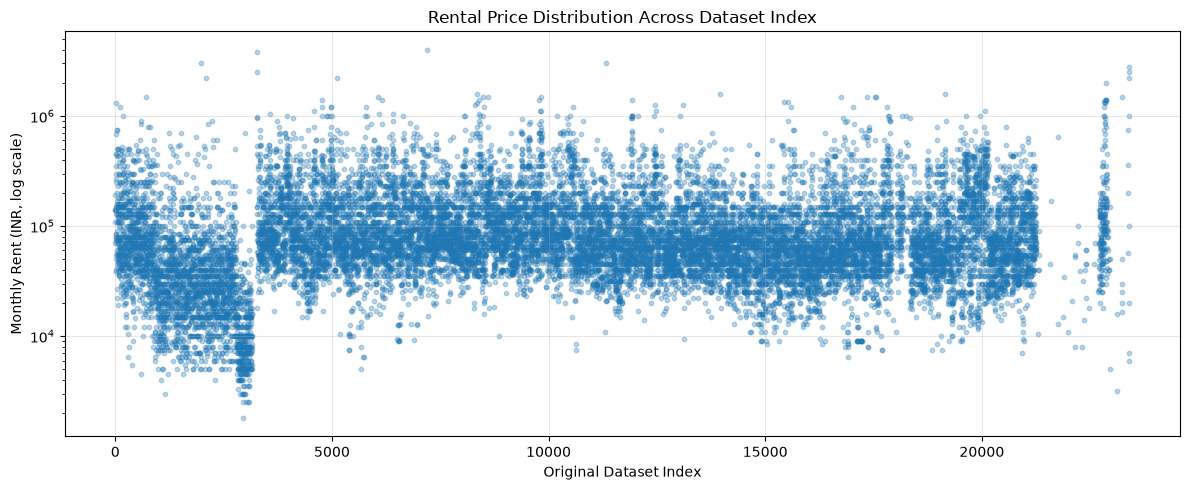

In [151]:
plt.figure(figsize=(12, 5))

plt.scatter(
    df_clean.index,
    df_clean["Price"],
    alpha=0.3,
    s=10
)

plt.yscale("log")

plt.xlabel("Original Dataset Index")
plt.ylabel("Monthly Rent (INR, log scale)")
plt.title("Rental Price Distribution Across Dataset Index")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [152]:
bhk_price_summary = (
    df_clean.groupby("BHK")["Price"]
    .agg(["count", "median", "mean"])
    .round(2)
)

print("Rental Price Statistics by BHK:")
print(bhk_price_summary)

Rental Price Statistics by BHK:
     count    median       mean
BHK                            
1.0   4655   35000.0   37818.69
2.0   8228   65000.0   73336.46
3.0   5423  130000.0  151573.66
4.0   1425  280000.0  335693.40
5.0    220  465000.0  557093.18
6.0     36  430000.0  699166.67
7.0      7  900000.0  967142.86


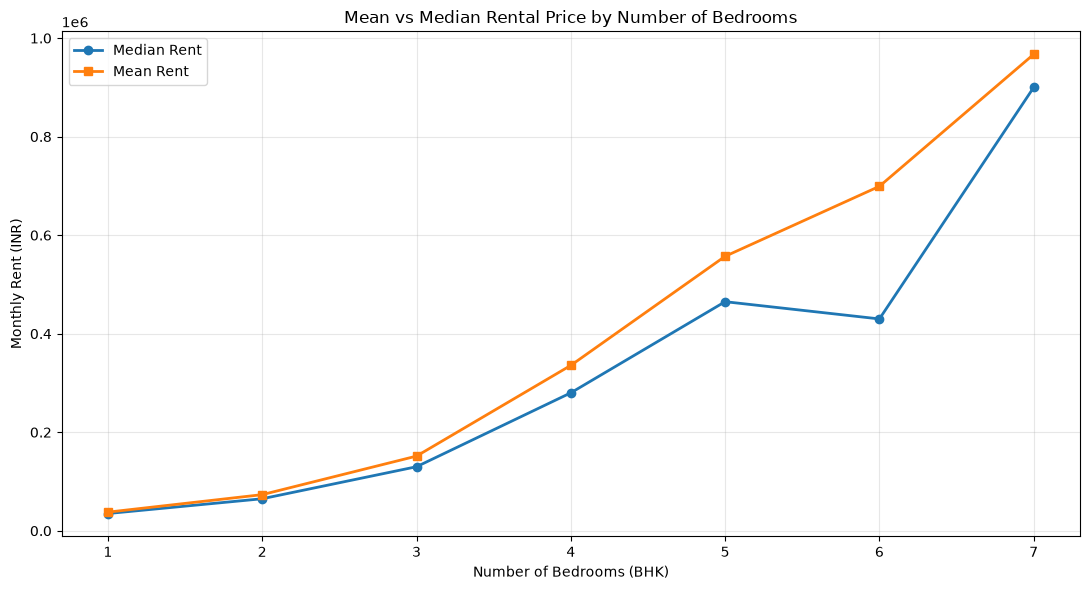

In [153]:
bhk_price_summary = (
    df_clean.groupby("BHK")["Price"]
    .agg(["count", "median", "mean"])
    .reset_index()
)

plt.figure(figsize=(11, 6))

plt.plot(
    bhk_price_summary["BHK"],
    bhk_price_summary["median"],
    marker="o",
    linewidth=2,
    label="Median Rent"
)

plt.plot(
    bhk_price_summary["BHK"],
    bhk_price_summary["mean"],
    marker="s",
    linewidth=2,
    label="Mean Rent"
)

plt.xlabel("Number of Bedrooms (BHK)")
plt.ylabel("Monthly Rent (INR)")
plt.title("Mean vs Median Rental Price by Number of Bedrooms")

plt.xticks(bhk_price_summary["BHK"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Rental prices generally increase with the number of bedrooms (BHK). Mean rents are consistently higher than median rents, suggesting a right-skewed distribution influenced by high-priced properties. The slight decrease in median rent for 6-BHK properties may be explained by the smaller sample size in this category.

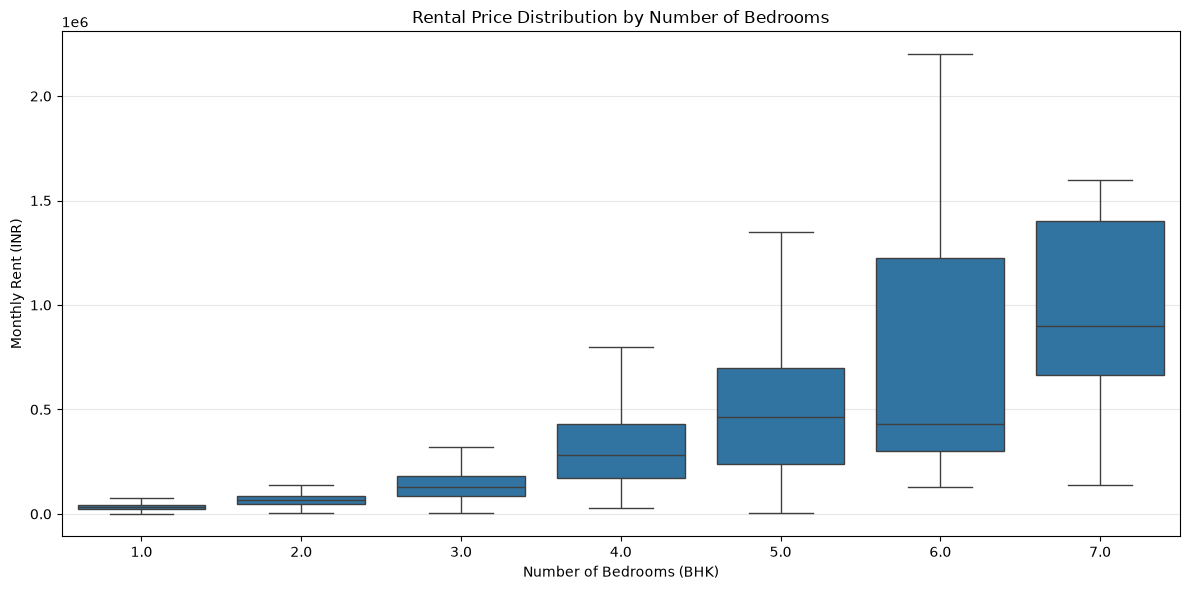

In [154]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_clean[df_clean["BHK"].between(1, 7)],
    x="BHK",
    y="Price",
    showfliers=False
)

plt.title("Rental Price Distribution by Number of Bedrooms")
plt.xlabel("Number of Bedrooms (BHK)")
plt.ylabel("Monthly Rent (INR)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [155]:
outlier_summary = []

for bhk in sorted(df_clean["BHK"].dropna().unique()):

    prices = df_clean.loc[df_clean["BHK"] == bhk, "Price"].dropna()

    q1 = prices.quantile(0.25)
    q3 = prices.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = prices[
        (prices < lower_bound) |
        (prices > upper_bound)
    ]

    outlier_summary.append({
        "BHK": bhk,
        "Total Properties": len(prices),
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(prices) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_summary)

print("Rental Price Outliers by BHK:")
print(outlier_df.to_string(index=False))

Rental Price Outliers by BHK:
 BHK  Total Properties  Lower Bound  Upper Bound  Outliers  Outlier Percentage
 1.0              4655     -10000.0      78000.0       189                4.06
 2.0              8228      -7500.0     140500.0       479                5.82
 3.0              5423     -57500.0     322500.0       369                6.80
 4.0              1425    -220000.0     820000.0        60                4.21
 5.0               220    -450000.0    1390000.0        10                4.55
 6.0                36   -1087500.0    2612500.0         0                0.00
 7.0                 7    -437500.0    2502500.0         0                0.00


In [156]:
extreme_outliers = []

for bhk in sorted(df_clean["BHK"].dropna().unique()):

    group = df_clean[df_clean["BHK"] == bhk]

    q1 = group["Price"].quantile(0.25)
    q3 = group["Price"].quantile(0.75)

    iqr = q3 - q1
    upper_bound = q3 + 3 * iqr

    extreme = group[group["Price"] > upper_bound].copy()

    extreme["Upper_Bound"] = upper_bound

    extreme_outliers.append(extreme)

extreme_outliers_df = pd.concat(extreme_outliers)

print("Number of extreme outliers:", len(extreme_outliers_df))

print(
    extreme_outliers_df[
        ["Title", "Price", "Area", "BHK",
         "Bathrooms", "Upper_Bound"]
    ]
    .sort_values("Price", ascending=False)
    .head(20)
    .to_string()
)

Number of extreme outliers: 228
                                                                                              Title      Price     Area  BHK  Bathrooms  Upper_Bound
7204                                          5BHK Multistorey Apartment for Rent in Altamount Road  4000000.0  10500.0  5.0        7.0    2080000.0
3269                                         2BHK Multistorey Apartment for Rent in Nalasopara East  3800000.0    650.0  2.0        1.0     196000.0
11328                                             5BHK Multistorey Apartment for Rent in Prabhadevi  3000000.0  14500.0  5.0        6.0    2080000.0
1987                                                     2BHK Villa for Rent in Tilak Nagar Chembur  3000000.0      NaN  2.0        2.0     196000.0
23385  5BHK Multistorey Apartment for Rent in Oberoi Three Sixty West at Hanuman Nagar Andheri East  2800000.0   6000.0  5.0        7.0    2080000.0
23401                                           1BHK Multistorey Apartment

In [157]:
df_clean["Suspicious_Price"] = False

# Flag extreme price outliers for properties with up to 3 bedrooms
suspicious_indices = extreme_outliers_df[
    extreme_outliers_df["BHK"].between(1, 3)
].index

df_clean.loc[suspicious_indices, "Suspicious_Price"] = True

print("Number of suspicious listings:")
print(df_clean["Suspicious_Price"].value_counts())

print("\nExamples of suspicious listings:")
print(
    df_clean.loc[
        df_clean["Suspicious_Price"],
        ["Title", "Price", "Area", "BHK", "Price_per_m2"]
    ]
    .sort_values("Price", ascending=False)
    .head(15)
    .to_string()
)

Number of suspicious listings:
Suspicious_Price
False    19966
True       215
Name: count, dtype: int64

Examples of suspicious listings:
                                                                              Title      Price    Area  BHK  Price_per_m2
3269                         2BHK Multistorey Apartment for Rent in Nalasopara East  3800000.0   650.0  2.0   5846.153846
1987                                     2BHK Villa for Rent in Tilak Nagar Chembur  3000000.0     NaN  2.0           NaN
3268                                        1BHK Multistorey Apartment for Rent in   2500000.0   655.0  1.0   3816.793893
23401                           1BHK Multistorey Apartment for Rent in Andheri West  2500000.0     NaN  1.0           NaN
23399                                     2BHK Builder Floor Apartment for Rent in   2200000.0     NaN  2.0           NaN
23226    1BHK Multistorey Apartment for Rent in Seven Eleven Apna Ghar at Mira Road  1500000.0   557.0  1.0   2692.998205
22829  3

In [158]:
print("Dataset shape:", df_clean.shape)

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nMissing values:")
print(df_clean.isna().sum())

print("\nInvalid prices:")
print((df_clean["Price"] <= 0).sum())

print("\nInvalid areas:")
print((df_clean["Area"] <= 0).sum())

print("\nSuspicious price listings:")
print(df_clean["Suspicious_Price"].sum())

Dataset shape: (20181, 20)

Duplicate rows:
0

Missing values:
Title                       0
Price                       0
Area                      629
BHK                       187
Bathrooms                  33
Furnished                  19
Balconies               10947
Floor                     794
Ownership                   0
Facing                      0
Amenities                   0
Transaction Type            0
Property Type               0
Location                    0
Year of Construction     5877
Is Luxury                   0
Description                 0
Property Image           2646
Price_per_m2              629
Suspicious_Price            0
dtype: int64

Invalid prices:
0

Invalid areas:
0

Suspicious price listings:
215


In [159]:
from pathlib import Path

output_path = Path("../data/cleaned/mumbai_rentals_cleaned.csv")

output_path.parent.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", output_path.resolve())
print("Dataset shape:", df_clean.shape)

Cleaned dataset saved successfully!
File location: C:\Users\ahmed\OneDrive\Documents\Group3-day1assignment\data\cleaned\mumbai_rentals_cleaned.csv
Dataset shape: (20181, 20)


Data Cleaning and Exploratory Data Analysis — Conclusions

The original dataset contained 23,405 rental property listings in Mumbai. After removing exact duplicates, 20,181 properties were retained for analysis.

The cleaning process included converting rental prices and property areas into numerical values, standardizing categorical information, and identifying missing or potentially inconsistent records.

Key findings:

Rental prices generally increase with the number of bedrooms (BHK).

Larger properties show greater rental price variability.

Some listings contain unusually high rental prices or potentially inconsistent property areas.

A total of 215 listings were flagged as suspicious based on extreme rental price thresholds for properties with one to three bedrooms.

Missing values remain in several variables, particularly balconies and year of construction.

Limitations:

Statistical outliers do not necessarily represent incorrect listings. Additionally, missing information and the absence of detailed neighborhood-level location data limit the precision of the analysis.

The cleaned dataset retains potentially suspicious observations for transparency and further investigation.